# §7 Experiments and Block Ablation

The model is used as a **measuring instrument** for the preparation decisions of §6: one estimator (L2
logistic regression, C frozen) is applied to every arm on the same stored folds, and each block is judged
against its locked hypothesis with paired intervals. Two populations get equal weight:

* **E-ALL** – the whole training part, label `L_comb` (84 % of the positives already know their diagnosis);
* **E-SCREEN** – people *not* told they have diabetes, positive = HbA1c ≥ 6.5 % (the screening use case).

The 20 % hold-out is **not** evaluated here; its single use is §9.11, after `exp-freeze`.

In [1]:
import sys, pathlib
_here = pathlib.Path.cwd()
ROOT = next(p for p in [_here, *_here.parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
from src import config as C, plots, results_io as R

import json, textwrap, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy import stats

from src import nhanes_io as io, labels as L, prep as P, evalkit as ek

from IPython.display import display
pd.set_option("display.width", 150, "display.max_columns", 30, "display.max_colwidth", 60)


def show(df, digits=3):
    """Display a table as HTML (long text wraps; keeps the text output narrow)."""
    display(df.style.hide(axis="index").format(precision=digits, na_rep="")
            .set_properties(**{"text-align": "left", "white-space": "normal"}))


OUT = C.RESULTS_DIR / "S7"
OUT.mkdir(parents=True, exist_ok=True)
import os
os.environ.setdefault("PYTHONWARNINGS", "ignore::UserWarning")   # silence worker-side solver warnings (counted in run_arm_cv)
N_JOBS = min(12, max(1, (os.cpu_count() or 2) - 2))
# FAST mode (re-run setting) uses fewer coefficient-bootstrap replicates than config.N_BOOT_COEF: the unscaled arms
# reach the solver's iteration limit in every refit, which makes this the slowest step of the section. FINAL is unchanged.
B_COEF = C.N_BOOT_COEF if C.IS_FINAL else 30
S7 = {"mode": C.NB_MODE, "cv": f"{C.CV_SPLITS}x{C.CV_REPEATS}", "n_boot": C.N_BOOT, "n_boot_coef": B_COEF}
T_START = time.time()
print(f"mode {C.NB_MODE}: {C.CV_SPLITS}x{C.CV_REPEATS} CV, B = {C.N_BOOT}, coefficient bootstrap B = {B_COEF}, {N_JOBS} workers")

mode FINAL: 5x5 CV, B = 1000, coefficient bootstrap B = 500, 12 workers


## 1 Splits
**Why.** Every arm must be scored on identical folds, otherwise paired differences mix model effects with
split noise. The hold-out (20 %, label × race stratified; created once at its first use in §6, DR-S6-12) and the
repeated stratified folds are stored with SHA-256 hashes and re-verified on every run. Folds are stratified on
the four label strata so that each fold holds a fair share of the 152 undiagnosed cases that define E-SCREEN.

In [2]:
raw = P.raw_cohort()
clean = L.add_labels(io.build_cohort())
assert (raw["SEQN"].to_numpy() == clean["SEQN"].to_numpy()).all()
tr, te = ek.make_holdout(clean)
raw_tr = raw.iloc[tr].reset_index(drop=True)
cl = clean.iloc[tr].reset_index(drop=True)
X = {1: P.raw_feature_frame(raw_tr, 1), 2: P.raw_feature_frame(raw_tr, 2)}
y = cl["L_comb"].to_numpy()
esc = cl["in_escreen"].eq(1).to_numpy()
y_esc = cl["y_escreen"].fillna(0).astype(int).to_numpy()   # only scored inside the E-SCREEN mask
strat = cl["stratum_3x3"].astype(str).to_numpy()
folds = ek.make_folds(y, strat)
n = len(y)
n_test_fold = n / C.CV_SPLITS
n_train_fold = n - n_test_fold
hold = json.loads((C.RESULTS_DIR / "splits" / "holdout.json").read_text(encoding="utf-8"))
print(f"training part {n:,} rows ({y.sum()} L_comb positives); hold-out {len(te):,} rows - not evaluated in S7")
print(f"E-SCREEN in training part: {esc.sum():,} rows, {y_esc[esc].sum()} positives (HbA1c >= 6.5, not diagnosed)")
print(f"folds: {len(folds)} = {folds.n_splits} x {folds.n_repeats}, hash {folds.hash[:16]}..., file {folds.path.name}")
print(f"hold-out test SEQN SHA-256 {hold['sha256_test_seqn'][:16]}...")
per_fold = pd.DataFrame([{"fold": i, "n_test": len(t), "pos_eall": int(y[t].sum()), "pos_escreen": int(y_esc[t][esc[t]].sum())}
                         for i, (_, t) in enumerate(folds)])
display(per_fold.describe().loc[["min", "mean", "max"], ["n_test", "pos_eall", "pos_escreen"]].round(1))
S7["splits"] = dict(n_train=n, n_holdout=len(te), n_pos_eall=int(y.sum()), n_escreen=int(esc.sum()),
                    n_pos_escreen=int(y_esc[esc].sum()), folds_hash=folds.hash, folds_file=folds.path.name,
                    holdout_sha256=hold["sha256_test_seqn"], pos_escreen_per_fold_min=int(per_fold["pos_escreen"].min()))

training part 4,584 rows (777 L_comb positives); hold-out 1,146 rows - not evaluated in S7
E-SCREEN in training part: 3,934 rows, 127 positives (HbA1c >= 6.5, not diagnosed)
folds: 25 = 5 x 5, hash 0d20f8f706ebf1e1..., file folds_FINAL.npz
hold-out test SEQN SHA-256 616fd0590bec7b92...


,n_test,pos_eall,pos_escreen
min,916.0,155.0,25.0
mean,916.8,155.4,25.4
max,917.0,156.0,26.0


**So what.** Each fold holds about 155 E-ALL positives but only about 24 E-SCREEN positives. E-SCREEN is
therefore scored on the pooled out-of-fold vector (paired bootstrap), not fold by fold, and most E-SCREEN
verdicts are expected to be inconclusive. The hold-out hash is printed so that §9.11 can prove it was untouched.

## 2 Data-justified model choice
**Why.** Only basic interpretable models are allowed (logistic regression and shallow trees). Within that constraint
each modelling choice is tied to a diagnostic number from the §4 model-justification table, with the reason for *not*
choosing the alternative.

In [3]:
S4dir = C.RESULTS_DIR / "S4"
lin = pd.read_csv(S4dir / "linearity_tests.csv")
inter = pd.read_csv(S4dir / "interaction_tests.csv")
daj = pd.read_csv(S4dir / "daj_table.csv")
vif4 = pd.read_csv(S4dir / "vif_table.csv")
print("§4 RCS linearity tests (4 knots vs linear, df 2):")
display(lin[["label", "n", "n_events", "chi2", "p", "nonlinear"]].round(4))
print("§4 interaction tests (primary spec A):")
display(inter[inter["spec"] == "A_primary"][["term", "chi2", "df", "p", "verdict"]].round(4))
sx = inter[inter["term"] == "sex_x_bmi"].set_index("spec")["p"].round(3).to_dict()
epv_den = {t: P.build_pipeline(P.ARMS["S"], t)[:-1].fit_transform(X[t]).shape[1] for t in (1, 2)}
epv = {t: round(y.sum() / k, 1) for t, k in epv_den.items()}
print(f"\nsex x BMI by spec: {sx}")
print(f"events per parameter in S: Tier 1 {y.sum()}/{epv_den[1]} = {epv[1]}, Tier 2 {y.sum()}/{epv_den[2]} = {epv[2]}")
print(f"imbalance: prevalence {y.mean():.3f} in the training part")
lin_i = lin.set_index("variable")
nl = ["RIDAGEYR", "BMXBMI", "LBDHDD", "LBXTC"]
ia = inter[inter["spec"] == "A_primary"].set_index("term")
vr = vif4[vif4["set"] == "raw_anthropometry"].set_index("variable")["vif"]
vb = vif4.loc[vif4["set"] == "bp_readings", "vif"]
ev_nonlin = ", ".join(f"{lin_i.loc[v, 'label']} {lin_i.loc[v, 'chi2']:.1f}" for v in nl) + f" (all p < {lin_i.loc[nl, 'p'].max():.3f})"
ev_inter = (f"race x BMI p {ia.loc['race_x_bmi', 'p']:.2f}, Asian x BMI p {ia.loc['asian_x_bmi', 'p']:.2f} "
            f"(MDE {ia.loc['asian_x_bmi', 'mde']:.2f} log-OR)")
ev_coll = f"weight VIF {vr['BMXWT']:.1f}, BMI {vr['BMXBMI']:.1f}; 6 BP readings {vb.min():.1f}-{vb.max():.1f}"
choice = pd.DataFrame([
    ("non-linearity", ev_nonlin, "L2 logistic regression + B-spline basis (P13)", "categorised bands (arbitrary cut-points, information loss); GAM / boosting (outside the allowed model class)"),
    ("interactions", ev_inter, "no interaction terms; Asian BMI bias treated as a measurement issue (P14, S8)", "interaction terms add variance without detectable gain"),
    ("collinearity", ev_coll, "aggregate + in-fold VIF pruning (P04/P05), L2 as second defence", "L1 (unstable selection among collinear columns, sensitivity only)"),
    ("sample size", f"{y.sum()} events / {epv_den[1]} parameters (EPV {epv[1]})", "unpenalised fit would be acceptable; mild L2 (C0) chosen by inner CV", "deep trees / ensembles (overfit, outside the allowed model class)"),
    ("imbalance", f"prevalence {y.mean():.1%}", "no resampling; class_weight tested as block B6a", "SMOTE (breaks calibration and the survey design)"),
    ("thresholds / leakage", "clinical cut-points and leakage need inspection", "depth-3 tree (min leaf 50) as a probe only", "tree as main model (step functions, unstable)"),
], columns=["diagnostic", "evidence (S4 / S7)", "decision", "why not the alternative"])
choice.to_csv(OUT / "model_choice.csv", index=False)
show(choice)
S7["model_choice"] = dict(linearity=lin.set_index("label")[["chi2", "p"]].round(4).to_dict("index"),
                          sex_x_bmi_p_by_spec=sx, epv=epv, n_params=epv_den)

§4 RCS linearity tests (4 knots vs linear, df 2):


,label,n,n_events,chi2,p,nonlinear
0,age,4478,722,57.6075,0.0000,True
1,BMI,4478,722,11.5618,0.0031,True
2,waist,4478,722,7.0540,0.0294,True
3,SBP (mean),4478,722,5.8698,0.0531,False
4,HDL,4478,722,18.4670,0.0001,True
5,total cholesterol,4478,722,41.7673,0.0000,True
6,PIR,4478,722,0.8344,0.6589,False


§4 interaction tests (primary spec A):


,term,chi2,df,p,verdict
0,race_x_bmi,5.1890,5,0.3933,not detected
1,asian_x_bmi,0.0071,1,0.9328,not detected
2,age_x_bmi,0.5829,1,0.4452,not detected
3,sex_x_bmi,6.9951,1,0.0082,detected



sex x BMI by spec: {'A_primary': 0.008, 'B_minimal': 0.833, 'C_splines': 0.072}
events per parameter in S: Tier 1 777/42 = 18.5, Tier 2 777/53 = 14.7
imbalance: prevalence 0.170 in the training part


diagnostic,evidence (S4 / S7),decision,why not the alternative
non-linearity,"age 57.6, BMI 11.6, HDL 18.5, total cholesterol 41.8 (all p < 0.003)",L2 logistic regression + B-spline basis (P13),"categorised bands (arbitrary cut-points, information loss); GAM / boosting (outside the allowed model class)"
interactions,"race x BMI p 0.39, Asian x BMI p 0.93 (MDE 0.70 log-OR)","no interaction terms; Asian BMI bias treated as a measurement issue (P14, S8)",interaction terms add variance without detectable gain
collinearity,"weight VIF 95.7, BMI 97.6; 6 BP readings 8.8-11.7","aggregate + in-fold VIF pruning (P04/P05), L2 as second defence","L1 (unstable selection among collinear columns, sensitivity only)"
sample size,777 events / 42 parameters (EPV 18.5),unpenalised fit would be acceptable; mild L2 (C0) chosen by inner CV,"deep trees / ensembles (overfit, outside the allowed model class)"
imbalance,prevalence 17.0%,no resampling; class_weight tested as block B6a,SMOTE (breaks calibration and the survey design)
thresholds / leakage,clinical cut-points and leakage need inspection,depth-3 tree (min leaf 50) as a probe only,"tree as main model (step functions, unstable)"


**So what.** Age, BMI and both lipids bend significantly, so the main model uses spline terms; the linear version
stays as the ablation arm *S-linear*. Race × BMI and Asian × BMI are not detected (underpowered: "not detected" is
not "absent"). Sex × BMI is significant in §4's primary specification only (p by specification printed above), so
no interaction term is added and the point is a limitation. With about 18 events per parameter overfitting risk is
modest; L2 mainly stabilises the correlated anthropometrics. In-fold VIF > 10 pruning with BMI and waist protected
(P05) removes only weight (§6.5).

## 3 Regularisation strength C0
**Why.** A fair minimal-versus-systematic comparison requires the *same model* in every arm. C is therefore chosen once – by
`LogisticRegressionCV(Cs=[0.01, 0.1, 1, 10])`, inner 5-fold ROC-AUC, on the S arm of Tier 1 with its class and
survey weights – and then frozen for every arm. Choosing it on S favours S slightly (the other arms do not get
their own tuning); M0 and M1 with their own C are a §9.4 sensitivity.

In [4]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold

cfgS = P.ARMS["S"]
design = P.build_pipeline(cfgS, 1)[:-1].fit_transform(X[1])
ylab = P.training_label(raw_tr, cfgS)
inner = StratifiedKFold(5, shuffle=True, random_state=ek.derive_seed(C.SEED_MASTER, "S7", "C0"))
with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    lrcv = LogisticRegressionCV(Cs=[0.01, 0.1, 1, 10], cv=inner, scoring="roc_auc", max_iter=C.LR_MAX_ITER,
                                class_weight="balanced", l1_ratios=(0.0,), use_legacy_attributes=False)
    lrcv.fit(design, ylab, sample_weight=P.survey_weights(raw_tr))
scores = np.asarray(lrcv.scores_).reshape(5, -1)   # (inner folds, Cs); l1_ratio fixed at 0 (pure L2)
C0 = float(np.ravel(lrcv.C_)[0])
cv_auc = pd.Series(scores.mean(axis=0).ravel()[:4], index=[0.01, 0.1, 1, 10]).round(4)
print("inner-CV ROC-AUC by C:"); print(cv_auc.to_string())
print(f"C0 = {C0} (frozen for all arms and tiers)")
S7["C0"] = dict(C0=C0, inner_cv_auc=cv_auc.to_dict())

inner-CV ROC-AUC by C:
0.01     0.8490
0.10     0.8519
1.00     0.8515
10.00    0.8514
C0 = 0.1 (frozen for all arms and tiers)


**So what.** The inner-CV AUC is almost flat across C (range about 0.003), so C is not a lever for the results below
and the optimism of tuning on S is small. Disclosure: C0 is selected once on the whole training part, not nested
inside the outer folds; with so flat a curve the resulting optimism is negligible.

## 4 Running the arms
**Why.** Each arm × tier is cross-validated on the stored folds with the frozen C0; every preparation step is
refitted inside each training fold. Arms with P02 off are trained on their own naive label (965 positives),
but every arm is scored against the frozen `L_comb`. The depth-3 tree is run on M0, M1 and S as a probe.
Solver non-convergence (the unscaled arms) is counted, not suppressed.

In [5]:
ARM_LIST = list(P.ARMS)
jobs = [(a, t, "lr") for t in (1, 2) for a in ARM_LIST] + [(a, t, "tree") for t in (1, 2) for a in ("M0", "M1", "S")]
t0 = time.time()
# one job per arm x tier x model, each deterministic: the number of workers changes the wall time only (FAST may use
# every core so that the re-run stays within about 5 minutes; FINAL keeps its worker count)
N_JOBS_ARMS = N_JOBS if C.IS_FINAL else max(N_JOBS, (os.cpu_count() or 2) - 2)
runs = Parallel(n_jobs=N_JOBS_ARMS)(delayed(P.run_arm_cv)(a, t, X[t], raw_tr, folds, C_=C0, model=m) for a, t, m in jobs)
OOF = {(r["arm"], r["tier"], r["model"]): r["oof"] for r in runs}
PM = {k: ek.mean_oof(v, n) for k, v in OOF.items()}          # repeat-averaged OOF probability per row
diag = pd.DataFrame([{k: r[k] for k in ("arm", "tier", "model", "n_convergence_warnings", "seconds", "n_pos_train_label")}
                     for r in runs])
assert all(np.isfinite(v).all() for v in PM.values())
for r in runs:   # no hold-out row can appear: OOF rows index the training part only
    assert r["oof"]["row"].max() < n and r["oof"].groupby("repeat")["row"].nunique().eq(n).all()
print(f"{len(jobs)} arm x tier x model runs, {sum(len(f) for f in [folds]) * len(jobs)} fits, {time.time() - t0:.0f} s wall")
print("runs with solver non-convergence (folds at the iteration limit):")
display(diag[diag["n_convergence_warnings"] > 0].round(1))
S7["runs"] = dict(n_runs=len(jobs), wall_seconds=time.time() - t0,
                  convergence=diag[diag["n_convergence_warnings"] > 0][["arm", "tier", "model", "n_convergence_warnings"]].to_dict("records"))

44 arm x tier x model runs, 1100 fits, 74 s wall
runs with solver non-convergence (folds at the iteration limit):


,arm,tier,model,n_convergence_warnings,seconds,n_pos_train_label
0,M0,1,lr,25,49.1,772
1,M1,1,lr,25,40.7,772
3,cum+B1,1,lr,25,40.5,777
4,cum+B3,1,lr,25,36.6,777
5,cum+B4,1,lr,25,37.5,777
12,S-B5,1,lr,25,37.2,777
19,M0,2,lr,24,48.2,772
20,M1,2,lr,25,40.8,772
22,cum+B1,2,lr,25,40.4,777
23,cum+B3,2,lr,25,37.7,777


In [6]:
from sklearn.metrics import roc_auc_score, average_precision_score

def pop_of(name):
    """(label vector, evaluation mask) of a population."""
    if name == "E-ALL":
        return y, np.ones(n, bool)
    if name == "E-SCREEN":
        return y_esc, esc
    if name == "PIR-missing":
        return y, cl["INDFMPIR"].isna().to_numpy()
    raise ValueError(name)

def _bacc05(yy, pp):
    pred = pp >= 0.5
    return 0.5 * (pred[yy == 1].mean() + (~pred[yy == 0]).mean())

def _calslope_dev(yy, pp):
    return abs(ek._calibration(yy, pp)[0] - 1.0)

METRIC_FN = {"roc_auc": roc_auc_score, "pr_auc": average_precision_score,
             "brier": lambda yy, pp: float(np.mean((pp - yy) ** 2)),
             "bacc05": _bacc05, "calslope_dev": _calslope_dev}

def auc_ci(p, pop="E-ALL", seed_tag="auc"):
    """AUC of a pooled OOF vector with a label-stratified bootstrap CI (paired against a constant 0.5)."""
    yy, m = pop_of(pop)
    b = ek.paired_bootstrap(yy, p, np.full(n, 0.5), "roc_auc", n_boot=C.N_BOOT, eval_mask=m,
                            seed=ek.derive_seed(C.SEED_MASTER, "S7", seed_tag, pop))
    return b["metric_a"], b["ci_low"] + 0.5, b["ci_high"] + 0.5

def arm_row(key):
    oof, pm = OOF[key], PM[key]
    fm = ek.fold_metrics(oof, y)
    out = {"arm": key[0], "tier": key[1], "model": key[2], "eall_auc_foldmean": fm["roc_auc"].mean(),
           "eall_auc_foldsd": fm["roc_auc"].std(ddof=1)}
    for pop in ("E-ALL", "E-SCREEN"):
        yy, m = pop_of(pop)
        ms = ek.metric_suite(yy[m], pm[m])
        a, lo, hi = auc_ci(pm, pop, seed_tag=f"{key}")
        tag = "eall" if pop == "E-ALL" else "escr"
        out.update({f"{tag}_auc": a, f"{tag}_auc_lo": lo, f"{tag}_auc_hi": hi, f"{tag}_pr_auc": ms["pr_auc"],
                    f"{tag}_brier": ms["brier"], f"{tag}_recall_spec80": ms["recall_at_spec"],
                    f"{tag}_cal_slope": ms["cal_slope"], f"{tag}_cal_citl": ms["cal_citl"], f"{tag}_prev": ms["prevalence"]})
    out["eall_auc_weighted"] = ek.metric_suite(y, pm, w=cl[C.WEIGHT_PHLEB].to_numpy())["roc_auc"]
    return out

arm_metrics = pd.DataFrame([arm_row(k) for k in OOF]).merge(diag, on=["arm", "tier", "model"])
arm_metrics.to_csv(OUT / "arm_metrics.csv", index=False)
cols_show = ["arm", "model", "eall_auc", "eall_auc_lo", "eall_auc_hi", "escr_auc", "escr_auc_lo", "escr_auc_hi",
             "eall_brier", "escr_recall_spec80", "eall_cal_slope", "n_convergence_warnings"]
main_arms = ["M0", "M1", "S", "T1-minus-care", "S-linear", "S+WHtR"]
tab = arm_metrics[(arm_metrics["tier"] == 1) & arm_metrics["arm"].isin(main_arms)]
print("Tier 1, main arms (all arms and Tier 2: results/S7/arm_metrics.csv):")
display(tab[cols_show].round(3))

Tier 1, main arms (all arms and Tier 2: results/S7/arm_metrics.csv):


,arm,model,eall_auc,eall_auc_lo,eall_auc_hi,escr_auc,escr_auc_lo,escr_auc_hi,eall_brier,escr_recall_spec80,eall_cal_slope,n_convergence_warnings
0,M0,lr,0.961,0.952,0.968,0.844,0.808,0.881,0.040,0.709,1.195,25
1,M1,lr,0.828,0.814,0.843,0.772,0.739,0.804,0.112,0.535,0.961,25
2,S,lr,0.836,0.822,0.849,0.781,0.748,0.809,0.185,0.520,0.867,0
15,T1-minus-care,lr,0.820,0.806,0.835,0.800,0.766,0.832,0.195,0.614,0.873,0
16,S-linear,lr,0.832,0.817,0.845,0.775,0.744,0.806,0.189,0.496,0.849,0
18,S+WHtR,lr,0.835,0.822,0.848,0.782,0.751,0.814,0.186,0.551,0.866,0
38,M0,tree,0.927,0.912,0.941,0.633,0.574,0.689,0.031,0.441,1.239,0
39,M1,tree,0.766,0.748,0.782,0.701,0.663,0.740,0.123,0.433,1.021,0
40,S,tree,0.768,0.751,0.784,0.683,0.646,0.720,0.190,0.354,0.963,0


**So what.** The paired comparisons below decide; three patterns are already visible. The naive arm M0 reaches
an E-ALL AUC near 0.96 that collapses once the availability rule is applied; all admissible arms sit in a narrow
band; and every arm loses discrimination on E-SCREEN. Only the unscaled arms (M0, M1, the cumulative steps before
B5, S−B5) stop at the solver's iteration limit – a cost of skipping scaling, examined post lock in §7.12.1.

### Comparison engine
Paired difference A − B of a metric on a population: fold-level Nadeau–Bengio corrected t and a paired,
label-stratified bootstrap on the repeat-averaged OOF vectors; on E-ALL the **wider** interval is used, on
E-SCREEN the bootstrap only. The estimate is always the same quantity per population: on E-ALL the mean of the
fold-level paired differences, on E-SCREEN the difference on the pooled OOF vector. The 80 %-power minimal detectable difference (MDD) is reported with each Δ. Verdict
rules are those locked in `governance/hypotheses.md`; for a directional claim an `evalkit` verdict of
"equivalent" (CI inside ±magnitude) means the claimed magnitude is excluded and is recorded as **refuted**.

In [7]:
def fold_values(key, metric, pop):
    yy, m = pop_of(pop)
    fn = METRIC_FN[metric]
    vals = {}
    for (r, f), g in OOF[key].groupby(["repeat", "fold"]):
        rows = g["row"].to_numpy()
        keep = m[rows]
        vals[(r, f)] = fn(yy[rows][keep], g["prob"].to_numpy()[keep])
    return pd.Series(vals)

def compare(a, b, tier=1, metric="roc_auc", pop="E-ALL", model="lr", pa=None, pb=None):
    """Paired comparison A - B; pa/pb override the OOF vectors (baselines)."""
    yy, m = pop_of(pop)
    pa = PM[(a, tier, model)] if pa is None else pa
    pb = PM[(b, tier, model)] if pb is None else pb
    bm = metric if metric in ("roc_auc", "brier", "pr_auc") else METRIC_FN[metric]
    bs = ek.paired_bootstrap(yy, pa, pb, bm, n_boot=C.N_BOOT, eval_mask=m,
                             seed=ek.derive_seed(C.SEED_MASTER, "S7", a, b, tier, metric, pop))
    row = dict(a=a, b=b, tier=tier, metric=metric, pop=pop, model=model, diff_pooled=bs["diff"],
               boot_lo=bs["ci_low"], boot_hi=bs["ci_high"], boot_se=bs["se"], n_eval=bs["n_eval"], n_pos=bs["n_pos"])
    if pop != "E-SCREEN" and (a, tier, model) in OOF and (b, tier, model) in OOF:
        d = (fold_values((a, tier, model), metric, pop) - fold_values((b, tier, model), metric, pop)).to_numpy()
        ct = ek.corrected_t(d, n_train_fold, n_test_fold)
        row.update(t_mean=ct["mean"], t_lo=ct["ci_low"], t_hi=ct["ci_high"], t_se=ct["se_corr"], t_p=ct["p"], J=ct["J"])
        use_t = (ct["ci_high"] - ct["ci_low"]) >= (bs["ci_high"] - bs["ci_low"])
        lo, hi, se = (ct["ci_low"], ct["ci_high"], ct["se_corr"]) if use_t else (bs["ci_low"], bs["ci_high"], bs["se"])
        est = ct["mean"]   # one estimand on E-ALL: the fold-mean paired difference (interval = the wider of the two)
        mdd = (stats.t.ppf(0.975, ct["df"]) + stats.t.ppf(0.80, ct["df"])) * se
        row["interval"] = "corrected_t" if use_t else "bootstrap"
    else:
        est, lo, hi, se = bs["diff"], bs["ci_low"], bs["ci_high"], bs["se"]
        mdd = (stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) * se
        row["interval"] = "bootstrap"
        if pop == "E-SCREEN" and (a, tier, model) in OOF and (b, tier, model) in OOF:
            ra = ek.repeat_metrics(OOF[(a, tier, model)], y_esc, eval_mask=esc).set_index("repeat")
            rb = ek.repeat_metrics(OOF[(b, tier, model)], y_esc, eval_mask=esc).set_index("repeat")
            if metric in ra:
                dr = ra[metric] - rb[metric]
                row.update(rep_min=dr.min(), rep_max=dr.max())
    row.update(est=est, lo=lo, hi=hi, se=se, mdd=mdd)
    return row

def v_equiv(lo, hi, s):
    return "supported" if (lo > -s and hi < s) else ("refuted" if (lo >= s or hi <= -s) else "inconclusive")

def v_dir(lo, hi, est, s, direction):
    v = ek.verdict(lo, hi, s, direction, est)
    return "refuted" if v == "equivalent" else v

def v_noninf(lo, hi, s):
    return "supported" if lo > -s else ("refuted" if hi < -s else "inconclusive")

COMP = []   # every comparison row, stored in results/S7/comparisons.csv

def cmp_(*args, label="", **kw):
    r = compare(*args, **kw)
    r["label"] = label
    COMP.append(r)
    return r

def fmt(r, k=3):
    return f"{r['est']:+.{k}f} [{r['lo']:+.{k}f}, {r['hi']:+.{k}f}] ({r['interval']}, MDD {r['mdd']:.{k}f})"

## 5 Leak gate: M0 → M1
**Why.** M0 keeps glucose, treatment, diagnosis history, prediabetes counselling (DIQ160) and prior glucose
testing (DIQ180). If the availability rule removes real leakage, discrimination must *drop* – a correct
deterioration (hypotheses H2a, B2). A depth-3 tree shows *where* the M0 signal comes from (B2t).

Tier 1 E-ALL    AUC M1 - M0 = -0.131 [-0.148, -0.114] (corrected_t, MDD 0.024)


Tier 1 E-SCREEN AUC M1 - M0 = -0.072 [-0.113, -0.031] (bootstrap, MDD 0.059)


Tier 2 E-ALL    AUC M1 - M0 = -0.119 [-0.133, -0.106] (corrected_t, MDD 0.019)


Tier 2 E-SCREEN AUC M1 - M0 = -0.081 [-0.120, -0.041] (bootstrap, MDD 0.056)


Tier 1 E-ALL    AUC S - (S-B2) = -0.122 [-0.138, -0.105] (corrected_t, MDD 0.023)


Tier 1 E-SCREEN AUC S - (S-B2) = -0.090 [-0.124, -0.060] (bootstrap, MDD 0.047)


arm,root_feature,variable,role,threshold,level2
M0,DIQ070_2.0,DIQ070,leak,0.500,"['DIQ180_2.0', 'DID040']"
M1,BPQ020_2.0,BPQ020,feature,0.500,"['BMXWAIST', 'BMXWAIST']"
S,BPQ020_1.0,BPQ020,feature,0.500,"['BMXWAIST', 'BMXWAIST']"


|--- taking diabetic pills: no <= 0.50
|   |--- blood-glucose test in past 3 years: no <= 0.50
|   |   |--- weights: [43.00, 17.00] class: 0
|   |--- blood-glucose test in past 3 years: no >  0.50
|   |   |--- LDL cholesterol (mg/dL) <= 119.50
|   |   |   |--- weights: [0.00, 430.00] class: 1
|   |   |--- LDL cholesterol (mg/dL) >  119.50
|   |   |   |--- weights: [3.00, 47.00] class: 1
|--- taking diabetic pills: no >  0.50
|   |--- age at diabetes diagnosis <= 49.50
|   |   |--- weights: [0.00, 90.00] class: 1
|   |--- age at diabetes diagnosis >  49.50
|   |   |--- age at diabetes diagnosis <= 50.50
|   |   |   |--- weights: [3766.00, 121.00] class: 0
|   |   |--- age at diabetes diagnosis >  50.50
|   |   |   |--- weights: [0.00, 67.00] class: 1

DID040 (age at diagnosis) is asked only of diagnosed people: missing for 86% of the training part, median-imputed to 50 in M0
tree E-SCREEN AUC: M0 0.633, M1 0.701, S 0.683
B2t verdict: supported


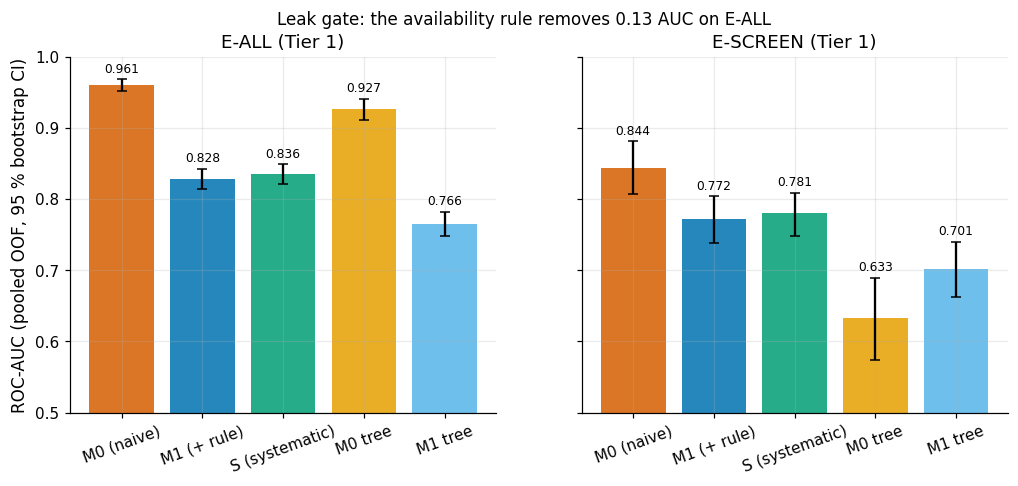

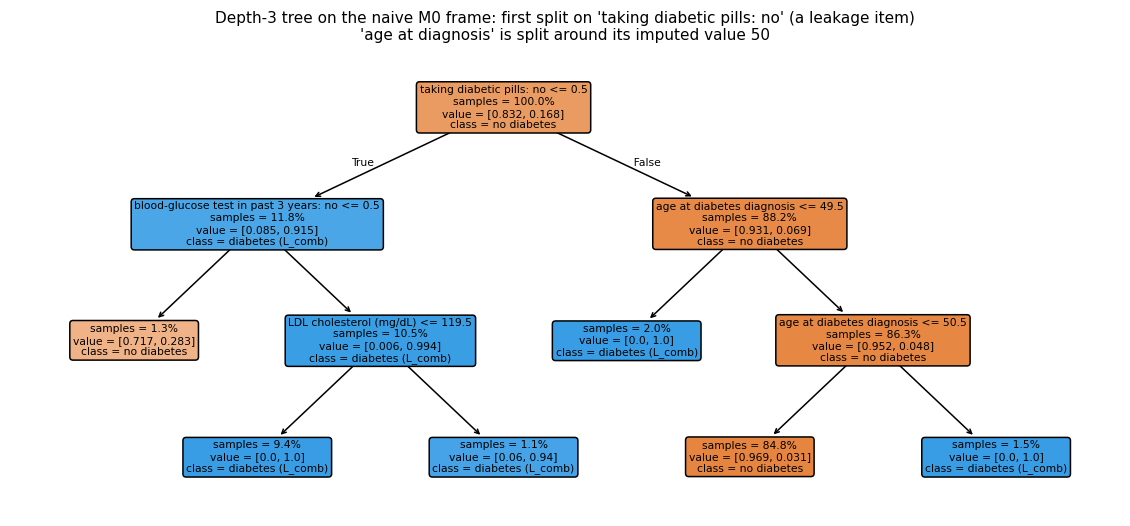

In [8]:
from sklearn.tree import plot_tree

gate = {}
for t in (1, 2):
    for pop in ("E-ALL", "E-SCREEN"):
        gate[(t, pop)] = cmp_("M1", "M0", t, "roc_auc", pop, label="B2 leak gate")
        print(f"Tier {t} {pop:8s} AUC M1 - M0 = {fmt(gate[(t, pop)])}")
for pop in ("E-ALL", "E-SCREEN"):
    r = cmp_("S", "S-B2", 1, "roc_auc", pop, label="B2 LOBO")
    print(f"Tier 1 {pop:8s} AUC S - (S-B2) = {fmt(r)}")

def base_var(name):
    for v in sorted(P._spec_by_var().index, key=len, reverse=True):
        if name == v or name.startswith(v + "_"):
            return v
    return name

roots, trees = {}, {}
for arm in ("M0", "M1", "S"):
    cfg = P.ARMS[arm]
    pipe = P.build_pipeline(cfg, 1, model="tree").fit(X[1], P.training_label(raw_tr, cfg), **P.fit_params(cfg, raw_tr))
    names = list(pipe[:-1].get_feature_names_out())
    tree = pipe[-1]
    trees[arm] = (tree, names)
    root = names[tree.tree_.feature[0]]
    rv = base_var(root)
    role = P._spec_by_var()["role"].get(rv, "derived")
    roots[arm] = dict(root_feature=root, variable=rv, role=role, threshold=float(tree.tree_.threshold[0]),
                      level2=[names[tree.tree_.feature[c]] for c in (tree.tree_.children_left[0], tree.tree_.children_right[0])
                              if tree.tree_.feature[c] >= 0])
show(pd.DataFrame(roots).T.rename_axis("arm").reset_index())
from sklearn.tree import export_text
m0_pipe = P.build_pipeline(P.ARMS["M0"], 1, model="tree").fit(X[1], P.training_label(raw_tr, P.ARMS["M0"]))
did040_fill = m0_pipe.named_steps["impute"].fill_["DID040"]
did040_miss = float(raw_tr["DID040"].isna().mean())
print(export_text(trees["M0"][0], feature_names=[P.plain_label(c) for c in trees["M0"][1]], show_weights=True))
print(f"DID040 (age at diagnosis) is asked only of diagnosed people: missing for {did040_miss:.0%} of the training part, "
      f"median-imputed to {did040_fill:.0f} in M0")
tree_escr = arm_metrics[(arm_metrics["tier"] == 1) & (arm_metrics["model"] == "tree")].set_index("arm")["escr_auc"]
print(f"tree E-SCREEN AUC: M0 {tree_escr['M0']:.3f}, M1 {tree_escr['M1']:.3f}, S {tree_escr['S']:.3f}")
S7["tree_m0"] = dict(did040_fill=did040_fill, did040_missing_share=did040_miss, escreen_auc=tree_escr.to_dict())
b2t = "supported" if roots["M0"]["role"] == "leak" and P._spec_by_var()["admissible"].get(roots["M1"]["variable"], "T1") != "N" else "refuted"
print(f"B2t verdict: {b2t}")
S7["leak_gate"] = {f"T{t}_{pop}": {k: gate[(t, pop)][k] for k in ("est", "lo", "hi", "interval", "mdd")} for (t, pop) in gate}
S7["tree_roots"] = roots

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
bars = [("M0", "lr", "M0 (naive)"), ("M1", "lr", "M1 (+ rule)"), ("S", "lr", "S (systematic)"), ("M0", "tree", "M0 tree"), ("M1", "tree", "M1 tree")]
colors = [C.OKABE_ITO["vermillion"], C.OKABE_ITO["blue"], C.OKABE_ITO["green"], C.OKABE_ITO["orange"], C.OKABE_ITO["sky"]]
for ax, pop, tag in zip(axes, ("E-ALL", "E-SCREEN"), ("eall", "escr")):
    sub = arm_metrics[arm_metrics["tier"] == 1].set_index(["arm", "model"])
    for i, ((a, m, _), c) in enumerate(zip(bars, colors)):
        v_ = sub.loc[(a, m)]
        ax.bar(i, v_[f"{tag}_auc"], color=c, alpha=0.85)
        ax.errorbar(i, v_[f"{tag}_auc"], yerr=[[v_[f"{tag}_auc"] - v_[f"{tag}_auc_lo"]], [v_[f"{tag}_auc_hi"] - v_[f"{tag}_auc"]]],
                    color="k", capsize=3)
        ax.text(i, v_[f"{tag}_auc_hi"] + 0.01, f"{v_[f'{tag}_auc']:.3f}", ha="center", fontsize=8)
    ax.set_xticks(range(len(bars)), [b[2] for b in bars], rotation=20)
    ax.set_ylim(0.5, 1.0)
    ax.set_title(f"{pop} (Tier 1)")
axes[0].set_ylabel("ROC-AUC (pooled OOF, 95 % bootstrap CI)")
fig.suptitle(f"Leak gate: the availability rule removes {-gate[(1, 'E-ALL')]['est']:.2f} AUC on E-ALL", fontsize=11)
plots.savefig(fig, "S7_leak_gate", caption="ROC-AUC of the naive arm M0, the availability-screened arm M1 and the systematic arm S "
              "(logistic regression) and of depth-3 trees, on E-ALL and E-SCREEN, Tier 1, with 95 % bootstrap CIs. "
              "The drop from M0 to M1 is the leakage removed by the availability rule.")
plt.show()

fig, ax = plt.subplots(figsize=(13, 5.5))
tree, names = trees["M0"]
plot_tree(tree, feature_names=[P.plain_label(c) for c in names], class_names=["no diabetes", "diabetes (L_comb)"],
          filled=True, impurity=False, proportion=True, rounded=True, fontsize=7, ax=ax)
ax.set_title(f"Depth-3 tree on the naive M0 frame: first split on '{P.plain_label(roots['M0']['root_feature'])}' "
             f"(a leakage item)\n'age at diagnosis' is split around its imputed value {did040_fill:.0f}", fontsize=10)
plots.savefig(fig, "S7_tree_m0", caption="Decision tree (depth 3, min leaf 50) fitted on the naive M0 feature frame (Tier 1, training part). "
              "The root split uses a treatment item that the availability rule removes; the splits at 49.5 / 50.5 on age at diagnosis "
              "isolate the median imputation of an item that is only asked of diagnosed people.")
plt.show()

**So what.** The availability rule removes the "too-good-to-be-true" signal: E-ALL AUC falls by about 0.13, far
beyond the 0.05 locked for B2/H2a. This **deterioration is the correct outcome** – M0 exploited treatment and
diagnosis history, i.e. the label leaking back in. The M0 tree's root is a *treatment* item, followed by prior
glucose testing and age at diagnosis. Age at diagnosis is asked only of the diagnosed; median imputation fills
everyone else with the printed constant, and the tree splits just below and above it. **Imputation has turned
skip-pattern missingness into a code for the label.** The leaked tree is even *worse* for screening than the M1
tree (E-SCREEN AUCs printed), and the drop is smaller on E-SCREEN, because the treatment items mark the already
diagnosed.

## 6 Baselines on E-SCREEN
**Why.** A model is only interesting if it beats what a clinician already has. The reduced ADA risk test (Bang et al.
2009) is the natural comparator on E-SCREEN, the screening population it was designed for. Mapping: age 0/1/2/3 for
<40/40–49/50–59/≥60; male +1; told high blood pressure (BPQ020) +1; physically inactive (no leisure-time moderate or
vigorous sessions, PAD790Q = PAD810Q = 0) +1; BMI 0/1/2/3 for <25/25–29.9/30–39.9/≥40. Family history and
gestational diabetes are not asked in 2021–23, so the score is **reduced (2 items missing)** and the published cut-off
is not used; AUC and recall at specificity 0.80 are compared instead. BL-ADAlite-LR refits weights to the same items
(trained on `L_comb` like every arm); BL0 is the no-information prior.

In [9]:
from sklearn.dummy import DummyClassifier

ada = P.ada_lite_items(cl)
OOF[("BL0", 1, "dummy")] = ek.cv_predict(lambda: DummyClassifier(strategy="prior"), X[1], y, folds)
PM[("BL0", 1, "dummy")] = ek.mean_oof(OOF[("BL0", 1, "dummy")], n)
bl0_fold = ek.fold_metrics(OOF[("BL0", 1, "dummy")], y)["roc_auc"]
assert np.allclose(bl0_fold, 0.5), "BL0 must have AUC 0.500 in every fold"
OOF[("BL-ADAlite-LR", 1, "lr")] = ek.cv_predict(lambda: P.ada_lr_pipeline(C0), ada, y, folds)
PM[("BL-ADAlite-LR", 1, "lr")] = ek.mean_oof(OOF[("BL-ADAlite-LR", 1, "lr")], n)
ada_score = ada["ada_score"].to_numpy(float)
PM[("BL-ADAlite", 1, "points")] = ada_score
miss = ada[["ada_htn_missing", "ada_inactive_missing", "ada_bmi_missing"]].sum().to_dict()
print(f"ADA-lite item availability: missing answers scored 0 -> {miss}")
print(f"ADA-lite score distribution in E-SCREEN: {pd.Series(ada_score[esc]).value_counts().sort_index().to_dict()}")

base_rows = []
for name, key in [("BL0 (prior)", ("BL0", 1, "dummy")), ("BL-ADAlite (points)", ("BL-ADAlite", 1, "points")),
                  ("BL-ADAlite-LR", ("BL-ADAlite-LR", 1, "lr")), ("M1", ("M1", 1, "lr")), ("S", ("S", 1, "lr")),
                  ("T1-minus-care", ("T1-minus-care", 1, "lr")), ("S Tier 2", ("S", 2, "lr"))]:
    p = PM[key]
    ms = ek.metric_suite(y_esc[esc], p[esc])
    a_, lo_, hi_ = auc_ci(p, "E-SCREEN", seed_tag=name)
    base_rows.append(dict(model=name, escr_auc=a_, lo=lo_, hi=hi_, escr_pr_auc=ms["pr_auc"],
                          escr_recall_spec80=ms["recall_at_spec"], eall_auc=roc_auc_score(y, p)))
baselines = pd.DataFrame(base_rows)
baselines.to_csv(OUT / "baselines_escreen.csv", index=False)
show(baselines, 3)
print(f"BL0 per-fold AUC (E-ALL): all exactly {bl0_fold.iloc[0]:.3f}; E-SCREEN prevalence {y_esc[esc].mean():.3f} = BL0 PR-AUC level")
h2c3 = cmp_("S", "BL-ADAlite", 1, "roc_auc", "E-SCREEN", pb=ada_score, label="H2c(iii)")
s_vs_adalr = cmp_("S", "BL-ADAlite-LR", 1, "roc_auc", "E-SCREEN", pb=PM[("BL-ADAlite-LR", 1, "lr")], label="S vs ADA-LR")
care_vs_ada = cmp_("T1-minus-care", "BL-ADAlite", 1, "roc_auc", "E-SCREEN", pb=ada_score, label="T1-minus-care vs ADA")
print(f"E-SCREEN AUC S - ADA-lite points = {fmt(h2c3)}")
print(f"E-SCREEN AUC S - ADA-lite-LR     = {fmt(s_vs_adalr)}")
print(f"E-SCREEN AUC T1-minus-care - ADA-lite points = {fmt(care_vs_ada)}")
adalr_vs_pts = {pop: cmp_("BL-ADAlite-LR", "BL-ADAlite", 1, "roc_auc", pop, pa=PM[("BL-ADAlite-LR", 1, "lr")], pb=ada_score,
                          label="ADA-LR vs ADA points") for pop in ("E-ALL", "E-SCREEN")}
for pop, r in adalr_vs_pts.items():
    print(f"{pop:8s} AUC ADA-lite-LR - ADA-lite points = {fmt(r)}")
S7["ada_lr_minus_points"] = {pop: {k: r[k] for k in ("est", "lo", "hi")} for pop, r in adalr_vs_pts.items()}
S7["baselines"] = baselines.set_index("model").to_dict("index")
S7["ada_missing_answers"] = miss

ADA-lite item availability: missing answers scored 0 -> {'ada_htn_missing': 4, 'ada_inactive_missing': 39, 'ada_bmi_missing': 62}
ADA-lite score distribution in E-SCREEN: {0.0: 171, 1.0: 353, 2.0: 513, 3.0: 675, 4.0: 695, 5.0: 666, 6.0: 512, 7.0: 271, 8.0: 69, 9.0: 9}


model,escr_auc,lo,hi,escr_pr_auc,escr_recall_spec80,eall_auc
BL0 (prior),0.497,0.443,0.546,0.031,0.134,0.503
BL-ADAlite (points),0.726,0.681,0.764,0.077,0.244,0.761
BL-ADAlite-LR,0.708,0.665,0.752,0.079,0.449,0.768
M1,0.772,0.738,0.804,0.093,0.535,0.828
S,0.781,0.747,0.812,0.091,0.520,0.836
T1-minus-care,0.800,0.769,0.831,0.108,0.614,0.820
S Tier 2,0.790,0.758,0.823,0.104,0.535,0.850


BL0 per-fold AUC (E-ALL): all exactly 0.500; E-SCREEN prevalence 0.032 = BL0 PR-AUC level


E-SCREEN AUC S - ADA-lite points = +0.055 [+0.026, +0.083] (bootstrap, MDD 0.041)
E-SCREEN AUC S - ADA-lite-LR     = +0.072 [+0.041, +0.103] (bootstrap, MDD 0.044)
E-SCREEN AUC T1-minus-care - ADA-lite points = +0.074 [+0.043, +0.106] (bootstrap, MDD 0.046)


E-ALL    AUC ADA-lite-LR - ADA-lite points = +0.006 [-0.001, +0.014] (bootstrap, MDD 0.010)
E-SCREEN AUC ADA-lite-LR - ADA-lite points = -0.018 [-0.032, -0.002] (bootstrap, MDD 0.021)


**So what.** BL0 sits at AUC 0.500 in every fold (asserted) and at the prevalence for PR-AUC, so the evaluation has
no built-in optimism. The reduced ADA score reaches an E-SCREEN AUC of about 0.73 with integer points and no
fitting; S is better by about 0.05 with a CI excluding 0 (H2c-iii). The one-shot hold-out does not replicate this
margin (§9.11), and ADA-lite lacks two items, so the margin likely overstates what a complete ADA test would concede.
Refitting the ADA items on `L_comb` (BL-ADAlite-LR) leaves E-ALL unchanged but *lowers* E-SCREEN AUC by about 0.02:
weights learned from a label dominated by known diabetics do not transfer to screening.

## 7 Cumulative path M0 → S
**Why.** The cumulative path shows how the AUC moves as blocks are added in the pre-specified order. Increments depend
on the order, so they are descriptive; verdicts come from leave-one-block-out (§7.8).

pop,step,est,lo,hi,interval,mdd
E-ALL,M0 -> M1,-0.1308,-0.1479,-0.1138,corrected_t,0.0241
E-ALL,M1 -> cum+B1,0.0009,-0.0021,0.0040,corrected_t,0.0043
E-ALL,cum+B1 -> cum+B3,0.0023,-0.0027,0.0074,corrected_t,0.0071
E-ALL,cum+B3 -> cum+B4,0.0007,-0.0011,0.0025,corrected_t,0.0025
E-ALL,cum+B4 -> cum+B5,0.0060,0.0011,0.0109,bootstrap,0.0074
E-ALL,cum+B5 -> cum+B6a,0.0006,-0.0011,0.0023,corrected_t,0.0025
E-ALL,cum+B6a -> S,-0.0027,-0.0062,0.0008,corrected_t,0.0050
E-SCREEN,M0 -> M1,-0.0718,-0.1133,-0.0310,bootstrap,0.0587
E-SCREEN,M1 -> cum+B1,0.0029,-0.0015,0.0071,bootstrap,0.0061
E-SCREEN,cum+B1 -> cum+B3,0.0041,-0.0036,0.0117,bootstrap,0.0108


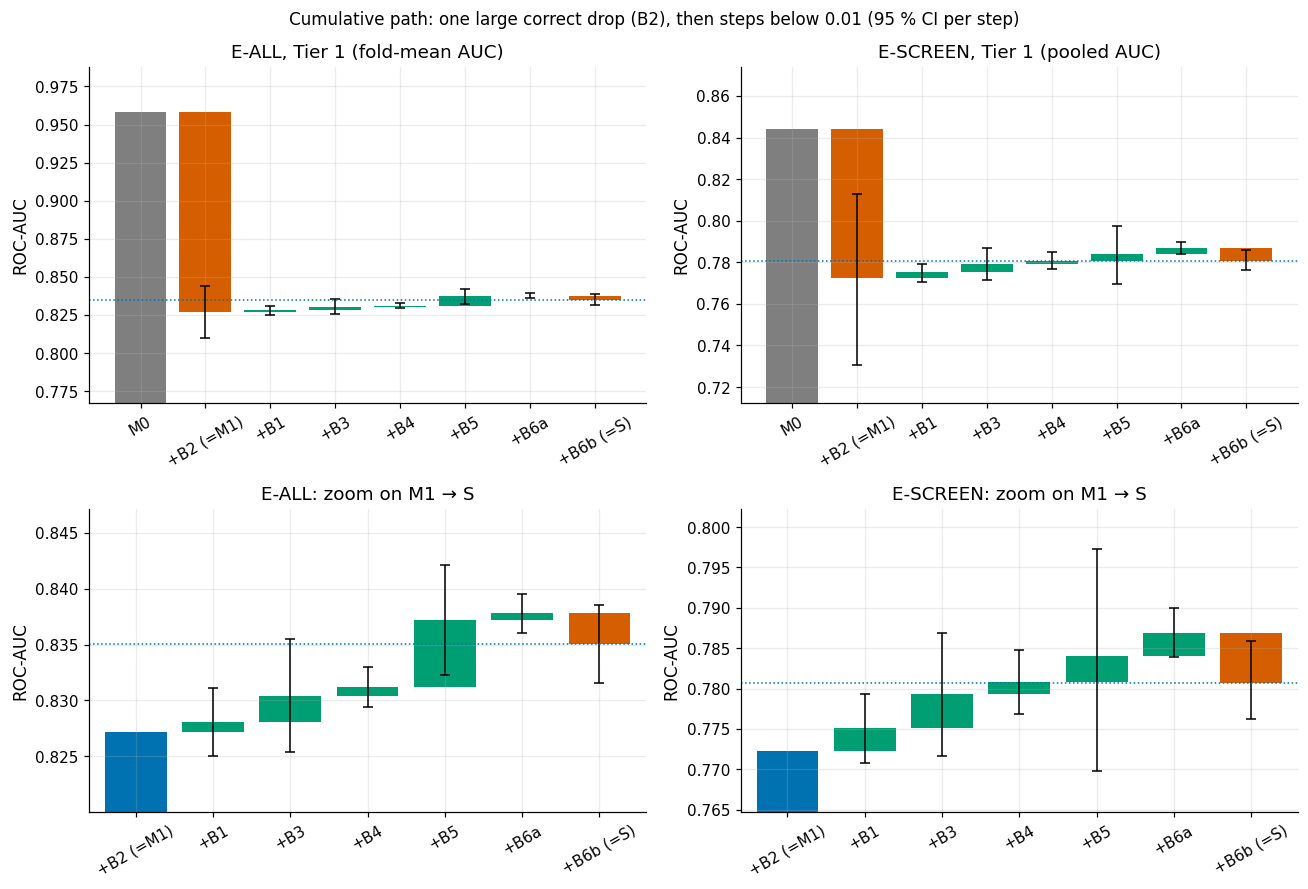

In [10]:
cum_rows = []
path = list(P.CUMULATIVE)
for t in (1, 2):
    for pop in ("E-ALL", "E-SCREEN"):
        for prev, cur in zip(path[:-1], path[1:]):
            r = cmp_(cur, prev, t, "roc_auc", pop, label="cumulative")
            r["step"] = f"{prev} -> {cur}"
            cum_rows.append(r)
cum = pd.DataFrame(cum_rows)
cum.to_csv(OUT / "cumulative_path.csv", index=False)
show(cum[cum["tier"] == 1][["pop", "step", "est", "lo", "hi", "interval", "mdd"]], 4)

fig, axes = plt.subplots(2, 2, figsize=(12, 8.2), gridspec_kw={"height_ratios": [1, 0.9]})
labels_ = ["M0", "+B2 (=M1)", "+B1", "+B3", "+B4", "+B5", "+B6a", "+B6b (=S)"]
sub = arm_metrics[(arm_metrics["tier"] == 1) & (arm_metrics["model"] == "lr")].set_index("arm")
for col, (pop, lev_col) in enumerate((("E-ALL", "eall_auc_foldmean"), ("E-SCREEN", "escr_auc"))):
    c = cum[(cum["tier"] == 1) & (cum["pop"] == pop)].reset_index(drop=True)
    levels = [sub.loc[path[0], lev_col]]
    for _, r in c.iterrows():
        levels.append(levels[-1] + r["est"])     # E-ALL: fold-mean steps; E-SCREEN: pooled steps
    for row, start in ((0, 0), (1, 1)):          # row 1 = zoom on M1 -> S
        ax = axes[row, col]
        ax.bar(start, levels[start], color=C.OKABE_ITO["grey"] if start == 0 else C.OKABE_ITO["blue"])
        for i in range(start, len(c)):
            r, d = c.loc[i], c.loc[i, "est"]
            ax.bar(i + 1, d, bottom=levels[i], color=C.OKABE_ITO["vermillion"] if d < 0 else C.OKABE_ITO["green"])
            ax.errorbar(i + 1, levels[i] + d, yerr=[[max(d - r["lo"], 0)], [max(r["hi"] - d, 0)]], color="k", capsize=3, lw=1)
        ax.axhline(levels[-1], color=C.OKABE_ITO["blue"], ls=":", lw=1)
        ax.set_xticks(range(start, len(labels_)), labels_[start:], rotation=30)
        span = [levels[k] + dlt for k in range(start, len(c)) for dlt in (0, c.loc[k, "lo"], c.loc[k, "hi"])]
        if row == 0:
            ax.set_ylim(min(levels) - 0.06, max(levels) + 0.03)
            ax.set_title(f"{pop}, Tier 1 ({'fold-mean' if pop == 'E-ALL' else 'pooled'} AUC)")
        else:
            ax.set_ylim(min(span) - 0.005, max(span) + 0.005)
            ax.set_xlim(start - 0.6, len(labels_) - 0.4)
            ax.set_title(f"{pop}: zoom on M1 → S")
        ax.set_ylabel("ROC-AUC")
fig.suptitle("Cumulative path: one large correct drop (B2), then steps below 0.01 (95 % CI per step)", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S7_waterfall", caption="Waterfall of the ROC-AUC along the cumulative path M0 -> +B2 -> +B1 -> +B3 -> +B4 -> +B5 -> +B6a -> +B6b (= S), "
              "Tier 1. E-ALL: fold-mean AUC and fold-mean paired differences with the conservative 95 % CI (wider of corrected t and "
              "bootstrap); E-SCREEN: pooled-OOF AUC and bootstrap CI. Bottom row: zoom on the steps after the leak gate. "
              "Red = decrease, green = increase; dotted line = S.")
plt.show()

**So what.** After the leak gate every block moves E-ALL AUC by less than the 0.01 SESOI, each step about the size of
its own MDD. The systematic pipeline does not "buy" discrimination; its value lies in fidelity, stability and
calibration, which is what the block hypotheses predicted and what §7.8–§7.11 test.

## 8 Leave-one-block-out
**Why.** The contribution of a block given every other step is S − (S without the block). These are the primary
block comparisons of the locked hypotheses, evaluated on both populations and both tiers, plus the extra arms
S-linear (splines only), S+WHtR (P14) and T1-minus-care.

pop,block,est,lo,hi,interval,mdd
E-ALL,B1,0.0019,-0.0011,0.0049,corrected_t,0.0042
E-ALL,B2,-0.1217,-0.1381,-0.1053,corrected_t,0.0232
E-ALL,B3,0.0019,-0.0018,0.0055,corrected_t,0.0051
E-ALL,B4,0.0002,-0.0019,0.0024,corrected_t,0.0030
E-ALL,B5,0.0065,0.0024,0.0107,bootstrap,0.0063
E-ALL,B6a,0.0006,-0.0017,0.0028,corrected_t,0.0032
E-ALL,B6b,-0.0027,-0.0062,0.0008,corrected_t,0.0050
E-ALL,splines,0.0038,0.0005,0.0074,bootstrap,0.0050
E-ALL,P14 WHtR,-0.0009,-0.0028,0.0009,corrected_t,0.0026
E-ALL,care items,0.0159,0.0094,0.0220,bootstrap,0.0095


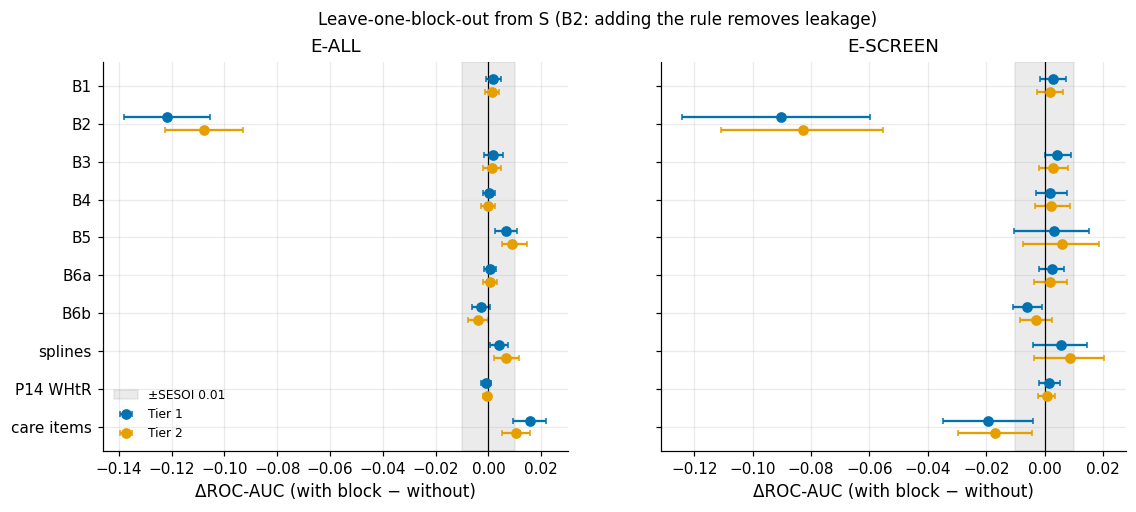

In [11]:
lobo_pairs = [("S", f"S-{b}", b) for b in P.BLOCKS] + [("S", "S-linear", "splines"), ("S+WHtR", "S", "P14 WHtR"),
                                                       ("S", "T1-minus-care", "care items")]
lobo_rows = []
for t in (1, 2):
    for pop in ("E-ALL", "E-SCREEN"):
        for a, b, lab in lobo_pairs:
            for metric in ("roc_auc", "pr_auc", "brier"):
                r = cmp_(a, b, t, metric, pop, label=f"LOBO {lab}")
                r["block"] = lab
                lobo_rows.append(r)
lobo = pd.DataFrame(lobo_rows)
lobo.to_csv(OUT / "lobo.csv", index=False)
v_ = lobo[(lobo["tier"] == 1) & (lobo["metric"] == "roc_auc")]
show(v_[["pop", "block", "est", "lo", "hi", "interval", "mdd"]], 4)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
order = [lab for _, _, lab in lobo_pairs]
for ax, pop in zip(axes, ("E-ALL", "E-SCREEN")):
    for t, off, col in ((1, -0.17, C.OKABE_ITO["blue"]), (2, 0.17, C.OKABE_ITO["orange"])):
        s = lobo[(lobo["tier"] == t) & (lobo["metric"] == "roc_auc") & (lobo["pop"] == pop)].set_index("block").loc[order]
        ax.errorbar(s["est"], np.arange(len(order)) + off, xerr=[s["est"] - s["lo"], s["hi"] - s["est"]], fmt="o",
                    color=col, capsize=2, label=f"Tier {t}")
    ax.axvspan(-C.SESOI["roc_auc"], C.SESOI["roc_auc"], color=C.OKABE_ITO["grey"], alpha=0.15, label="±SESOI 0.01")
    ax.axvline(0, color="k", lw=0.8)
    ax.set_yticks(range(len(order)), order)
    ax.set_xlabel("ΔROC-AUC (with block − without)")
    ax.set_title(pop)
axes[0].invert_yaxis()
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("Leave-one-block-out from S (B2: adding the rule removes leakage)", fontsize=11)
plots.savefig(fig, "S7_lobo", caption="Leave-one-block-out ΔROC-AUC = AUC(arm with the block) − AUC(arm without it) with conservative 95 % CIs, Tier 1 (blue) and "
              "Tier 2 (orange), E-ALL and E-SCREEN; grey band = ±SESOI 0.01. Every row is 'with − without': B2 is negative because adding the "
              "rule removes leakage; 'care items' = S − T1-minus-care (S keeps BPQ020/BPQ080); 'P14 WHtR' = S+WHtR − S.")
plt.show()

**So what.** Apart from B2 (negative because adding the rule removes leakage), block effects on discrimination are
small; their intervals decide between "equivalent" (inside the grey band) and "inconclusive" (crossing it). The
striking line is **care items** ("told high blood pressure / high cholesterol"): keeping them helps on E-ALL but
*hurts* on E-SCREEN. They help to recognise people the health system already knows, which is not the screening task.

## 9 E-ALL vs E-SCREEN
**Why.** 84 % of the `L_comb` positives already know their diagnosis, so an AUC on E-ALL largely measures how well a
model recognises *known* patients, who carry traces of care. The screening question is E-SCREEN. The gap between the
two is the pre-registered H2c(i).

S (Tier 1): AUC E-ALL 0.836 - E-SCREEN 0.781 = +0.055 [+0.028, +0.086] (bootstrap, MDD 0.040)
same 3,807 negatives in both populations; positives: E-ALL 777 (all L_comb), E-SCREEN 127 (undiagnosed only)
gap lower bound 0.028 vs pre-registered magnitude 0.03


arm,eall,eall_lo,eall_hi,escr,escr_lo,escr_hi,gap
M0,0.961,0.952,0.968,0.844,0.809,0.879,0.117
M1,0.828,0.814,0.841,0.772,0.739,0.804,0.056
S,0.836,0.822,0.848,0.781,0.746,0.812,0.055
S-linear,0.832,0.818,0.845,0.775,0.741,0.807,0.057
T1-minus-care,0.820,0.808,0.835,0.800,0.766,0.831,0.020
S+WHtR,0.835,0.821,0.847,0.782,0.749,0.814,0.053
S (T2),0.850,0.836,0.863,0.790,0.756,0.821,0.060
BL-ADAlite-LR,0.768,0.750,0.786,0.708,0.666,0.750,0.060
BL-ADAlite,0.761,0.745,0.778,0.726,0.687,0.769,0.035


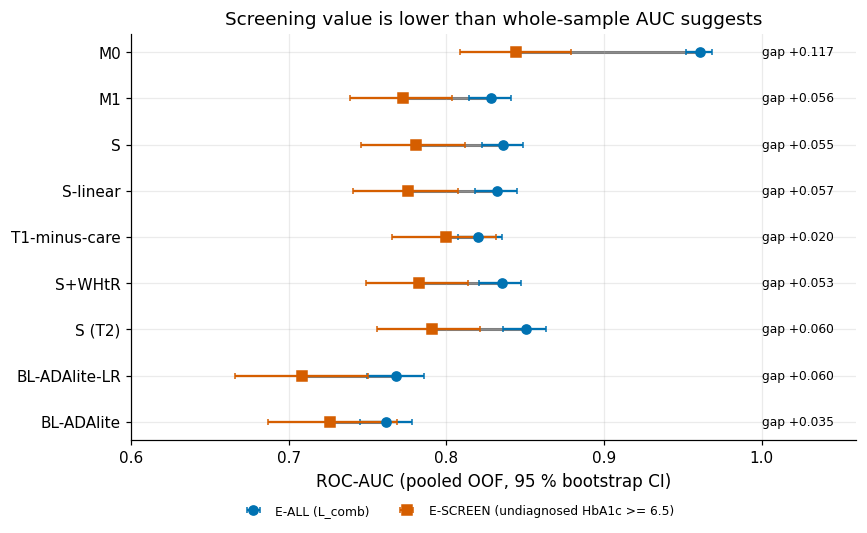

In [12]:
rng = np.random.default_rng(ek.derive_seed(C.SEED_MASTER, "S7", "H2c-i"))
groups = [np.flatnonzero(strat == s) for s in np.unique(strat)]
pS = PM[("S", 1, "lr")]
gaps = []
for _ in range(C.N_BOOT):
    idx = np.concatenate([rng.choice(g, len(g)) for g in groups])
    e = idx[esc[idx]]
    gaps.append(roc_auc_score(y[idx], pS[idx]) - roc_auc_score(y_esc[e], pS[e]))
gaps = np.array(gaps)
gap_obs = roc_auc_score(y, pS) - roc_auc_score(y_esc[esc], pS[esc])
gap_lo, gap_hi = np.percentile(gaps, [2.5, 97.5])
h2c1 = dict(a="S", b="S", tier=1, metric="roc_auc", pop="E-ALL minus E-SCREEN", est=gap_obs, lo=gap_lo, hi=gap_hi,
            se=gaps.std(ddof=1), interval="bootstrap", mdd=(stats.norm.ppf(0.975) + stats.norm.ppf(0.8)) * gaps.std(ddof=1),
            label="H2c(i)")
COMP.append(h2c1)
print(f"S (Tier 1): AUC E-ALL {roc_auc_score(y, pS):.3f} - E-SCREEN {roc_auc_score(y_esc[esc], pS[esc]):.3f} = {fmt(h2c1)}")
neg_eall, neg_escr = set(np.flatnonzero(y == 0)), set(np.flatnonzero(esc & (y_esc == 0)))
assert neg_eall == neg_escr, "E-ALL and E-SCREEN must share the same negatives"
print(f"same {len(neg_eall):,} negatives in both populations; positives: E-ALL {int(y.sum())} (all L_comb), "
      f"E-SCREEN {int(y_esc[esc].sum())} (undiagnosed only)")
print(f"gap lower bound {h2c1['lo']:.3f} vs pre-registered magnitude 0.03")

pairs = [("M0", 1, "lr"), ("M1", 1, "lr"), ("S", 1, "lr"), ("S-linear", 1, "lr"), ("T1-minus-care", 1, "lr"),
         ("S+WHtR", 1, "lr"), ("S", 2, "lr"), ("BL-ADAlite-LR", 1, "lr"), ("BL-ADAlite", 1, "points")]
dumb = []
for k in pairs:
    a1, l1, h1 = auc_ci(PM[k], "E-ALL", seed_tag=f"d{k}")
    a2, l2, h2 = auc_ci(PM[k], "E-SCREEN", seed_tag=f"d{k}")
    dumb.append(dict(arm=f"{k[0]}" + (" (T2)" if k[1] == 2 else ""), eall=a1, eall_lo=l1, eall_hi=h1, escr=a2, escr_lo=l2, escr_hi=h2))
dumb = pd.DataFrame(dumb)
dumb["gap"] = dumb["eall"] - dumb["escr"]
dumb.to_csv(OUT / "eall_vs_escreen.csv", index=False)
show(dumb, 3)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
for i, r in dumb.iterrows():
    ax.plot([r["escr"], r["eall"]], [i, i], color=C.OKABE_ITO["grey"], lw=2, zorder=1)
    ax.errorbar(r["eall"], i, xerr=[[r["eall"] - r["eall_lo"]], [r["eall_hi"] - r["eall"]]], fmt="o", color=C.OKABE_ITO["blue"],
                capsize=2, label="E-ALL (L_comb)" if i == 0 else None, zorder=2)
    ax.errorbar(r["escr"], i, xerr=[[r["escr"] - r["escr_lo"]], [r["escr_hi"] - r["escr"]]], fmt="s", color=C.OKABE_ITO["vermillion"],
                capsize=2, label="E-SCREEN (undiagnosed HbA1c >= 6.5)" if i == 0 else None, zorder=2)
    ax.text(1.0, i, f"gap {r['gap']:+.3f}", va="center", fontsize=8)
ax.set_yticks(range(len(dumb)), dumb["arm"])
ax.invert_yaxis()
ax.set_xlim(0.6, 1.06)
ax.set_xlabel("ROC-AUC (pooled OOF, 95 % bootstrap CI)")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.13), ncol=2, fontsize=8, frameon=False)
ax.set_title("Screening value is lower than whole-sample AUC suggests")
plots.savefig(fig, "S7_eall_vs_escreen", caption="ROC-AUC on E-ALL (blue, L_comb, 84 % already diagnosed) and E-SCREEN (red, people not told they have "
              "diabetes, positive = HbA1c >= 6.5 %) for the main arms and baselines, Tier 1 unless marked, with 95 % bootstrap CIs.")
plt.show()

**So what.** The two populations share exactly the same negatives (asserted); only the positives differ, so the gap
is pure **spectrum bias** (Ransohoff & Feinstein 1978): known diabetics, with treatment, care contacts and higher
HbA1c, are easier to rank than the undiagnosed. For S the gap is about 0.055 (H2c-i supported); its lower bound
(about 0.028) sits just below the pre-registered 0.03. The smaller gaps of T1-minus-care and ADA-lite are the mirror
image: the less a model relies on care traces, the less it loses. A whole-sample AUC overstates screening value –
the label composition, not the model, sets the headline number.

## 10 Precision–recall and calibration
**Why.** AUC ignores prevalence and calibration. E-SCREEN has a prevalence of about 3 %, so precision binds in
screening, and a model trained on `L_comb` (17 %) is miscalibrated there by design; class weights (B6a) inflate
probabilities further.

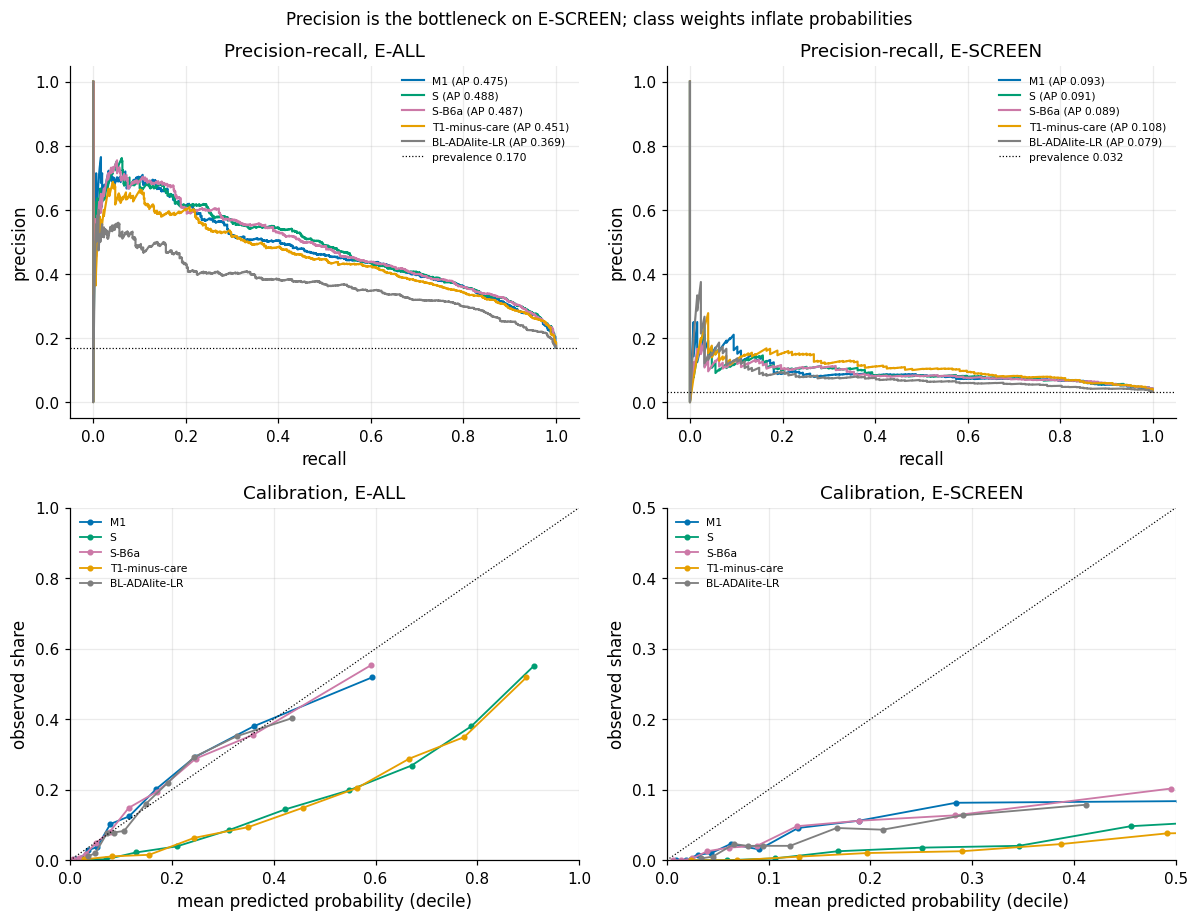

arm,pop,cal_slope,cal_citl,brier,mean_p,prevalence
M1,E-ALL,0.961,0.010,0.112,0.168,0.170
S,E-ALL,0.867,-1.818,0.185,0.409,0.170
S-B6a,E-ALL,0.979,0.027,0.110,0.167,0.170
T1-minus-care,E-ALL,0.873,-1.807,0.195,0.422,0.170
BL-ADAlite-LR,E-ALL,1.124,-0.001,0.123,0.170,0.170
M1,E-SCREEN,0.685,-1.814,0.056,0.136,0.032
S,E-SCREEN,0.613,-3.671,0.196,0.357,0.032
S-B6a,E-SCREEN,0.688,-1.783,0.055,0.133,0.032
T1-minus-care,E-SCREEN,0.723,-3.684,0.205,0.376,0.032
BL-ADAlite-LR,E-SCREEN,0.831,-1.799,0.054,0.152,0.032


In [13]:
from sklearn.metrics import precision_recall_curve
from sklearn.calibration import calibration_curve

curve_keys = [("M1", 1, "lr", C.OKABE_ITO["blue"]), ("S", 1, "lr", C.OKABE_ITO["green"]),
              ("S-B6a", 1, "lr", C.OKABE_ITO["purple"]), ("T1-minus-care", 1, "lr", C.OKABE_ITO["orange"]),
              ("BL-ADAlite-LR", 1, "lr", C.OKABE_ITO["grey"])]
fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
cal_rows = []
for col, pop in enumerate(("E-ALL", "E-SCREEN")):
    yy, m = pop_of(pop)
    for a, t, mdl, colr in curve_keys:
        p = PM[(a, t, mdl)][m]
        prec, rec, _ = precision_recall_curve(yy[m], p)
        axes[0, col].plot(rec, prec, color=colr, lw=1.4, label=f"{a} (AP {average_precision_score(yy[m], p):.3f})")
        fr, mp = calibration_curve(yy[m], p, n_bins=10, strategy="quantile")
        axes[1, col].plot(mp, fr, "o-", color=colr, ms=3, lw=1.2, label=a)
        ms_ = ek.metric_suite(yy[m], p)
        cal_rows.append(dict(arm=a, pop=pop, cal_slope=ms_["cal_slope"], cal_citl=ms_["cal_citl"], brier=ms_["brier"],
                             mean_p=float(p.mean()), prevalence=float(yy[m].mean())))
    axes[0, col].axhline(yy[m].mean(), color="k", ls=":", lw=0.8, label=f"prevalence {yy[m].mean():.3f}")
    axes[0, col].set(xlabel="recall", ylabel="precision", title=f"Precision-recall, {pop}")
    axes[0, col].legend(fontsize=7)
    lim = 1.0 if pop == "E-ALL" else 0.5
    axes[1, col].plot([0, lim], [0, lim], color="k", lw=0.8, ls=":")
    axes[1, col].set(xlabel="mean predicted probability (decile)", ylabel="observed share", title=f"Calibration, {pop}",
                     xlim=(0, lim), ylim=(0, lim))
    axes[1, col].legend(fontsize=7)
fig.suptitle("Precision is the bottleneck on E-SCREEN; class weights inflate probabilities", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S7_pr_calibration", caption="Top: precision-recall curves (average precision in the legend; dotted line = prevalence). Bottom: "
              "calibration by deciles of the predicted probability. Left E-ALL, right E-SCREEN; Tier 1 pooled OOF predictions. S uses "
              "balanced class weights; S-B6a is S without them.")
plt.show()
cal = pd.DataFrame(cal_rows)
cal.to_csv(OUT / "calibration.csv", index=False)
show(cal, 3)

**So what.** On E-SCREEN average precision is only about 0.1 against a prevalence of about 0.03: a screening tool
built on these items would mostly flag people without diabetes. The calibration panels show the price of class
weights – S predicts far above the observed prevalence, while S−B6a (no class weights) is close to the diagonal on
E-ALL. On E-SCREEN every model over-predicts, having been trained where 17 % are positive.

## 11 Coefficient stability
**Why.** Discrimination can hide unstable explanations: collinear anthropometrics share the BMI signal differently in
every resample. A nonparametric bootstrap of the whole pipeline (B = 500 in FINAL, 30 in FAST) measures this. BMI is
compared per SD across the arms in which it enters linearly (S is represented by S-linear, as locked); B3-b compares
S-linear−B3 with S-linear, H2b(c) compares M1 with S-linear.

arm,bmi_coef_per_sd,bmi_sd_per_sd,bmi_q_low,bmi_q_high,bmi_sign_flip,max_flip_anthro,anthro_in_model,n_coef,n_valid,share_flip_gt_10pct
M1,0.585,0.301,-0.164,1.075,0.120,0.822,"BMXBMI,BMXWT,BMXHT,BMXWAIST",46,500,0.391
cum+B1,0.240,0.354,-0.160,1.186,0.124,0.348,"BMXBMI,BMXWT,BMXHT,BMXWAIST",46,500,0.457
cum+B3,0.407,0.124,0.199,0.694,0.000,0.134,"BMXBMI,BMXHT,BMXWAIST",29,500,0.276
S-linear-B3,0.338,0.207,0.041,0.917,0.010,0.092,"BMXBMI,BMXWT,BMXHT,BMXWAIST",50,337,0.500
S-linear,0.699,0.152,0.433,1.035,0.000,0.484,"BMXBMI,BMXHT,BMXWAIST",34,500,0.353


SD ratio BMI S-linear-B3 / S-linear: 1.36, Monte Carlo interval [1.23, 1.50] (B = 500) -> refuted
SD ratio BMI M1 / S-linear: 1.98, Monte Carlo interval [1.80, 2.17] (B = 500) -> inconclusive
SD ratio BMI cum+B1 / cum+B3: 2.87, Monte Carlo interval [2.62, 3.12] (B = 500) -> supported


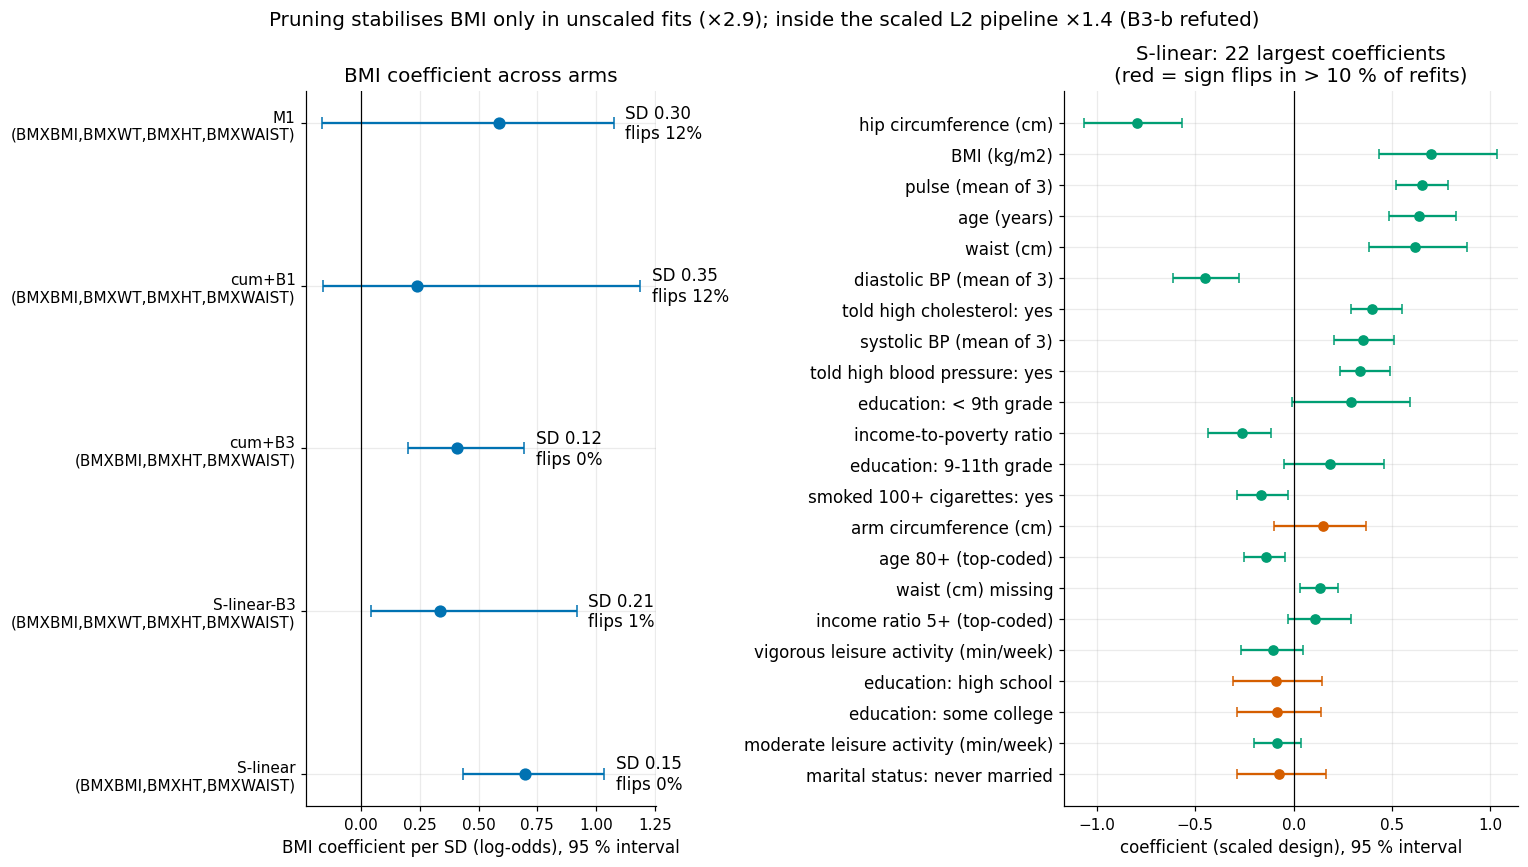

In [14]:
coef_arms = ["M1", "cum+B1", "cum+B3", "S-linear-B3", "S-linear"]
CB, coef_rows = {}, []
for arm in coef_arms:
    cfg = P.ARMS[arm]
    ylab_ = P.training_label(raw_tr, cfg)
    mk = (lambda cfg=cfg: P.build_pipeline(cfg, 1, C_=C0))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        cb = ek.coef_bootstrap(mk, X[1], ylab_, n_boot=B_COEF, seed=ek.derive_seed(C.SEED_MASTER, "S7", "coef", arm),
                               fit_params=P.fit_params(cfg, raw_tr), n_jobs=N_JOBS)
        dsg = mk()[:-1].fit_transform(X[1])
    sd_bmi = float(dsg["BMXBMI"].std(ddof=0))
    CB[arm] = (cb, sd_bmi)
    s = cb.summary
    anth = [c for c in ("BMXBMI", "BMXWT", "BMXHT", "BMXWAIST") if c in s.index]
    coef_rows.append(dict(arm=arm, bmi_coef_per_sd=s.loc["BMXBMI", "coef"] * sd_bmi, bmi_sd_per_sd=s.loc["BMXBMI", "sd"] * sd_bmi,
                          bmi_q_low=s.loc["BMXBMI", "q_low"] * sd_bmi, bmi_q_high=s.loc["BMXBMI", "q_high"] * sd_bmi,
                          bmi_sign_flip=s.loc["BMXBMI", "sign_flip_rate"], max_flip_anthro=s.loc[anth, "sign_flip_rate"].max(),
                          anthro_in_model=",".join(anth), n_coef=len(s), n_valid=int(s["n_valid"].min()),
                          share_flip_gt_10pct=float((s["sign_flip_rate"] > 0.10).mean())))
coef_tab = pd.DataFrame(coef_rows)
coef_tab.to_csv(OUT / "coef_stability.csv", index=False)
show(coef_tab, 3)

def sd_ratio(arm_a, arm_b, n_rs=2000):
    """SD(BMI per SD) of arm_a over arm_b with a Monte Carlo interval from resampling the B bootstrap replicates.

    The interval reflects the Monte Carlo error of the two SD estimates for the given number of replicates B (it narrows
    as B grows); it is not a sampling interval of the population ratio.
    """
    (ca, fa), (cb_, fb) = CB[arm_a], CB[arm_b]
    xa = ca.coefs["BMXBMI"].dropna().to_numpy() * fa
    xb = cb_.coefs["BMXBMI"].dropna().to_numpy() * fb
    r = np.random.default_rng(ek.derive_seed(C.SEED_MASTER, "S7", "ratio", arm_a, arm_b))
    rs = [xa[r.integers(0, len(xa), len(xa))].std(ddof=1) / xb[r.integers(0, len(xb), len(xb))].std(ddof=1) for _ in range(n_rs)]
    lo, hi = np.percentile(rs, [2.5, 97.5])
    return dict(a=arm_a, b=arm_b, ratio=xa.std(ddof=1) / xb.std(ddof=1), lo=lo, hi=hi)

def v_ratio(d, thr=C.SESOI["coef_sd_ratio"]):
    return "supported" if (d["ratio"] >= thr and d["lo"] > 1) else ("refuted" if d["hi"] < thr else "inconclusive")

ratio_b3 = sd_ratio("S-linear-B3", "S-linear")
ratio_h2b = sd_ratio("M1", "S-linear")
ratio_cum = sd_ratio("cum+B1", "cum+B3")
for d in (ratio_b3, ratio_h2b, ratio_cum):
    print(f"SD ratio BMI {d['a']} / {d['b']}: {d['ratio']:.2f}, Monte Carlo interval [{d['lo']:.2f}, {d['hi']:.2f}] "
          f"(B = {B_COEF}) -> {v_ratio(d)}")

fig, axes = plt.subplots(1, 2, figsize=(14, 8), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
for i, r in coef_tab.iterrows():
    ax.errorbar(r["bmi_coef_per_sd"], i, xerr=[[r["bmi_coef_per_sd"] - r["bmi_q_low"]], [r["bmi_q_high"] - r["bmi_coef_per_sd"]]],
                fmt="o", color=C.OKABE_ITO["blue"], capsize=4, ms=7)
    ax.text(r["bmi_q_high"] + 0.05, i, f"SD {r['bmi_sd_per_sd']:.2f}\nflips {r['bmi_sign_flip']:.0%}", va="center", fontsize=11)
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(range(len(coef_tab)), [f"{a}\n({x})" for a, x in zip(coef_tab["arm"], coef_tab["anthro_in_model"])], fontsize=10)
ax.invert_yaxis()
ax.set_xlabel("BMI coefficient per SD (log-odds), 95 % interval", fontsize=11)
ax.set_title("BMI coefficient across arms", fontsize=13)
cbS, _ = CB["S-linear"]
ref_levels = {f"{v}_{float(cl[v].mode().iloc[0]) if pd.api.types.is_numeric_dtype(cl[v]) else cl[v].mode().iloc[0]}"
              for v in P.categorical_columns() if v in cl.columns and cl[v].notna().any()}
disp = cbS.summary.drop(index=[c for c in cbS.summary.index if c in ref_levels])   # reference level of each category dropped
s = disp.reindex(disp["coef"].abs().sort_values(ascending=False).index)[:22]
ax = axes[1]
for i, (nm, r) in enumerate(s.iterrows()):
    colr = C.OKABE_ITO["vermillion"] if r["sign_flip_rate"] > 0.10 else C.OKABE_ITO["green"]
    ax.errorbar(r["coef"], i, xerr=[[r["coef"] - r["q_low"]], [r["q_high"] - r["coef"]]], fmt="o", color=colr, capsize=3, ms=6)
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(range(len(s)), [P.plain_label(c)[:38] for c in s.index], fontsize=11)
ax.invert_yaxis()
ax.tick_params(axis="x", labelsize=10)
ax.set_xlabel("coefficient (scaled design), 95 % interval", fontsize=11)
ax.set_title("S-linear: 22 largest coefficients\n(red = sign flips in > 10 % of refits)", fontsize=13)
fig.suptitle(f"Pruning stabilises BMI only in unscaled fits (×{ratio_cum['ratio']:.1f}); inside the scaled L2 pipeline "
             f"×{ratio_b3['ratio']:.1f} (B3-b {v_ratio(ratio_b3)})", fontsize=13)
fig.tight_layout()
plots.savefig(fig, "S7_coef_forest", caption="Left: bootstrap distribution (point = full-data fit, bar = 2.5-97.5 percentile) of the BMI coefficient per SD in the arms "
              "where BMI enters linearly, with the anthropometric columns present in each arm. Right: the 22 largest coefficients of S-linear "
              "(most frequent level of each category omitted for display); "
              f"red = sign flips in more than 10 % of the {B_COEF} bootstrap refits. Tier 1, training part.")
plt.show()
S7["coef_stability"] = dict(table=coef_tab.set_index("arm").to_dict("index"), ratio_B3=ratio_b3, ratio_H2b=ratio_h2b, ratio_cumulative=ratio_cum)

**So what.** Where weight, height and BMI enter together, BMI shares its signal with its formula partners: in the
unscaled arms (M1, cum+B1) its intervals cross zero and it flips sign in about one resample in eight. M1 is about
twice as unstable as S-linear, but that ratio's interval straddles the locked factor 2 (H2b-c inconclusive). Inside
the scaled L2 pipeline pruning adds little: the B3 ratio is about 1.4 with an interval excluding 2 (B3-b
**refuted**). B3-c fails for a mechanical reason – after pruning the near-zero *height* coefficient flips in about
half of the resamples by construction. Discrimination is the same in all these arms (§7.8); only the stability of
the explanation differs. The ratio intervals are Monte Carlo intervals (simulation error, not sampling uncertainty).

### Post-hoc: penalty and stability
**Why.** *Not pre-registered; added after an independent audit; no verdict changes.* The B3 ratio is computed under the
frozen C0, and the unscaled ratios come from fits that stop at the iteration limit. Re-running the B3 contrast at
weaker penalties shows how much stabilisation the L2 penalty already provides.

In [15]:
C_grid = [C0, 1.0, 100.0, 1e4]
B_s = 200 if C.IS_FINAL else 20   # replicates per arm and C (exploratory; FAST re-run mode uses fewer)
cs_rows = []
for c_ in C_grid:
    sd_ = {}
    for arm in ("S-linear-B3", "S-linear"):
        cfg = P.ARMS[arm]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            cb_ = ek.coef_bootstrap(lambda cfg=cfg, c_=c_: P.build_pipeline(cfg, 1, C_=c_), X[1], P.training_label(raw_tr, cfg),
                                    n_boot=B_s, seed=ek.derive_seed(C.SEED_MASTER, "S7", "Csens", arm, str(c_)),
                                    fit_params=P.fit_params(cfg, raw_tr), n_jobs=N_JOBS)
        sd_[arm] = float(cb_.coefs["BMXBMI"].std(ddof=1))
    cs_rows.append(dict(C=c_, sd_bmi_without_B3=sd_["S-linear-B3"], sd_bmi_with_B3=sd_["S-linear"],
                        ratio=sd_["S-linear-B3"] / sd_["S-linear"]))
c_sens = pd.DataFrame(cs_rows)
c_sens.to_csv(OUT / "posthoc_c_sensitivity.csv", index=False)
conv = diag[(diag["tier"] == 1) & (diag["model"] == "lr") & diag["arm"].isin(["M1", "cum+B1", "cum+B3"])]
print(f"post-hoc, scaled arms, B = {B_s} per C (per-SD BMI coefficient):")
show(c_sens, 3)
print("unscaled arms behind the larger ratios - CV folds ending at the iteration limit: "
      + ", ".join(f"{a} {k}/{len(folds)}" for a, k in zip(conv["arm"], conv["n_convergence_warnings"])))
S7["posthoc_c_sensitivity"] = dict(table=c_sens.to_dict("records"), unscaled_nonconvergence=dict(zip(conv["arm"], conv["n_convergence_warnings"].astype(int))),
                                   n_folds=len(folds), note="post hoc, exploratory, no verdict change")

post-hoc, scaled arms, B = 200 per C (per-SD BMI coefficient):


C,sd_bmi_without_B3,sd_bmi_with_B3,ratio
0.100,0.208,0.164,1.268
1.000,0.576,0.210,2.741
100.000,0.764,0.228,3.350
10000.000,0.834,0.213,3.916


unscaled arms behind the larger ratios - CV folds ending at the iteration limit: M1 25/25, cum+B1 25/25, cum+B3 25/25


**So what (exploratory).** As the penalty is relaxed towards an unpenalised fit the B3 ratio grows several-fold, so
the L2 penalty and pruning are partly *substitutes*. The large unscaled ratios (cum+B1/cum+B3; M1/S-linear behind
H2b-c) come from fits that hit the iteration limit in every fold: part of their spread is optimiser noise, so they
are not used to argue for B3.

## 12 Verdicts
**Why.** Each locked hypothesis gets exactly one verdict from its locked rule: the primary evaluation is E-ALL, Tier 1;
E-SCREEN and Tier 2 can only turn a decisive verdict into "mixed" by contradicting it. Verdict lines are generated
from the results. A FAST re-run (5 × 2, B = 100) reproduces every leakage, equivalence and class-weight verdict;
borderline ones (B3-b, B5-a, H2b) can move between "inconclusive" and a decisive verdict.

In [16]:
def lrtest_splines(tier=1):
    """Likelihood-ratio test spline bases vs linear terms (unpenalised logit, S design, training part)."""
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import log_loss
    cfg = P.ARMS["S"]
    yl = P.training_label(raw_tr, cfg)
    dS = P.build_pipeline(cfg, tier)[:-1].fit_transform(X[tier])
    dL = P.build_pipeline({**cfg, "P08": False}, tier)[:-1].set_params(p13__enabled=False).fit_transform(X[tier])
    spl_cols = [c for c in dS.columns if "_sp" in c]
    lin = [c.split("_sp")[0] for c in spl_cols]
    base = [c for c in dS.columns if c not in spl_cols]
    dL = pd.concat([dS[base], dL[sorted(set(lin))]], axis=1)
    ll = {}
    for nm, d in (("spline", dS), ("linear", dL)):
        m = LogisticRegression(C=1e8, max_iter=20000).fit(d, yl)
        ll[nm] = -log_loss(yl, m.predict_proba(d)[:, 1], normalize=False)
    df_ = len(spl_cols) - len(set(lin))
    chi2 = 2 * (ll["spline"] - ll["linear"])
    return dict(chi2=chi2, df=df_, p=float(stats.chi2.sf(chi2, df_)))

lrt = {t: lrtest_splines(t) for t in (1, 2)}
for t_, r_ in lrt.items():
    print(f"B5(d) LR test splines vs linear, Tier {t_}: chi2 {r_['chi2']:.1f}, df {r_['df']}, p {r_['p']:.2g}")

def get(a, b, metric="roc_auc", pop="E-ALL", tier=1, **kw):
    return cmp_(a, b, tier, metric, pop, label="verdict", **kw)

SB = []   # scoreboard rows
def add(hyp, sub, r, verdict, sesoi, role="primary"):
    SB.append(dict(hyp_id=hyp, sub=sub, role=role, comparison=f"{r.get('a')} - {r.get('b')}", metric=r.get("metric"),
                   pop=r.get("pop"), tier=r.get("tier"), est=r.get("est"), lo=r.get("lo"), hi=r.get("hi"),
                   interval=r.get("interval"), mdd=r.get("mdd"), sesoi=sesoi, verdict=verdict))

def equiv_claim(hyp, sub, a, b, s=0.01, metric="roc_auc"):
    for pop, tier, role in (("E-ALL", 1, "primary"), ("E-SCREEN", 1, "secondary"), ("E-ALL", 2, "secondary")):
        r = get(a, b, metric, pop, tier)
        add(hyp, sub, r, v_equiv(r["lo"], r["hi"], s), s, role)

def dir_claim(hyp, sub, a, b, s, direction, metric="roc_auc", falsifier=None, pops=(("E-ALL", 1, "primary"), ("E-SCREEN", 1, "secondary"), ("E-ALL", 2, "secondary")), **kw):
    for pop, tier, role in pops:
        r = get(a, b, metric, pop, tier, **kw)
        v = v_dir(r["lo"], r["hi"], r["est"], s, direction)
        if falsifier is not None and falsifier(r):
            v = "refuted"
        add(hyp, sub, r, v, s, role)

# B1
equiv_claim("B1", "(a) AUC", "S", "S-B1")
# B2 (leak gate, falsifier: CI lower bound above -0.05)
dir_claim("B2", "(a) AUC M1-M0", "M1", "M0", 0.05, "-", falsifier=lambda r: r["lo"] > -0.05)
SB.append(dict(hyp_id="B2t", sub="root split", role="primary", comparison=f"M0 root {roots['M0']['root_feature']} ({roots['M0']['role']}); "
               f"M1 root {roots['M1']['root_feature']}", metric="tree", pop="training part", tier=1, verdict=b2t))
# B3
equiv_claim("B3", "(a) AUC", "S", "S-B3")
SB.append(dict(hyp_id="B3", sub="(b) BMI SD ratio", role="primary", comparison="S-linear-B3 / S-linear", metric="sd_ratio",
               pop="training part", tier=1, est=ratio_b3["ratio"], lo=ratio_b3["lo"], hi=ratio_b3["hi"], sesoi=2.0, verdict=v_ratio(ratio_b3)))
fa = coef_tab.set_index("arm")
flip_v = "supported" if fa.loc["S-linear", "max_flip_anthro"] < fa.loc["S-linear-B3", "max_flip_anthro"] else (
    "inconclusive" if fa.loc["S-linear", "max_flip_anthro"] == fa.loc["S-linear-B3", "max_flip_anthro"] else "refuted")
SB.append(dict(hyp_id="B3", sub="(c) max sign-flip rate", role="primary", comparison="S-linear vs S-linear-B3", metric="sign_flip",
               pop="training part", tier=1, est=fa.loc["S-linear", "max_flip_anthro"], lo=fa.loc["S-linear-B3", "max_flip_anthro"],
               verdict=flip_v))
# B4
equiv_claim("B4", "(a) AUC", "S", "S-B4")
dir_claim("B4", "(b) Brier, PIR missing", "S", "S-B4", 0.005, "-", metric="brier", falsifier=lambda r: r["lo"] > -0.005,
          pops=(("PIR-missing", 1, "primary"), ("PIR-missing", 2, "secondary")))
# B5
dir_claim("B5", "(a) |cal slope - 1|", "S", "S-B5", 0.0, "-", metric="calslope_dev", falsifier=lambda r: r["lo"] > 0)
equiv_claim("B5", "(b) AUC block", "S", "S-B5")
equiv_claim("B5", "(c) AUC splines", "S", "S-linear")
SB.append(dict(hyp_id="B5", sub="(d) LR test splines", role="primary", comparison="S spline vs linear terms", metric="LR chi2",
               pop="training part", tier=1, est=lrt[1]["chi2"], lo=lrt[1]["p"], verdict="supported" if lrt[1]["p"] < 0.05 else "refuted"))
SB.append(dict(hyp_id="B5", sub="(e) tree P08/P09", role="primary", comparison="S tree with/without P08,P09", metric="max |dp|",
               pop="training part", tier=1, est=json.loads((C.RESULTS_DIR / "metrics_S6.json").read_text(encoding="utf-8"))["assertions"]["tree_p08_p09_maxabs"],
               verdict="supported"))
# B6a
equiv_claim("B6a", "(a) AUC", "S", "S-B6a")
dir_claim("B6a", "(b) Brier", "S", "S-B6a", 0.005, "+", metric="brier")
dir_claim("B6a", "(c) balanced accuracy at 0.5", "S", "S-B6a", 0.05, "+", metric="bacc05")
# B6b
for pop, tier, role in (("E-ALL", 1, "primary"), ("E-SCREEN", 1, "secondary"), ("E-ALL", 2, "secondary")):
    r = get("S", "S-B6b", "roc_auc", pop, tier)
    add("B6b", "(a) unweighted AUC", r, v_noninf(r["lo"], r["hi"], 0.01), 0.01, role)
# P14
equiv_claim("P14", "(a) AUC", "S+WHtR", "S")
SB.append(dict(hyp_id="P14", sub="(b) Asian TPR@spec0.80", role="primary", comparison="S+WHtR - S", metric="TPR", pop="Asian",
               verdict="deferred to S8"))
# H2a
dir_claim("H2a", "AUC M0-M1", "M0", "M1", 0.05, "+", falsifier=lambda r: r["hi"] < 0.05)
# H2b
equiv_claim("H2b", "(a) AUC", "S", "M1")
equiv_claim("H2b", "(b) Brier", "S", "M1", s=0.005, metric="brier")
SB.append(dict(hyp_id="H2b", sub="(c) BMI SD ratio", role="primary", comparison="M1 / S-linear", metric="sd_ratio", pop="training part",
               tier=1, est=ratio_h2b["ratio"], lo=ratio_h2b["lo"], hi=ratio_h2b["hi"], sesoi=2.0, verdict=v_ratio(ratio_h2b)))
# H2c
add("H2c", "(i) AUC E-ALL - E-SCREEN (S)", h2c1, v_dir(h2c1["lo"], h2c1["hi"], h2c1["est"], 0.03, "+"), 0.03)
r = get("T1-minus-care", "S", "roc_auc", "E-ALL", 1)
add("H2c", "(ii) minus care, E-ALL", r, v_dir(r["lo"], r["hi"], r["est"], 0.01, "-"), 0.01)
r = get("T1-minus-care", "S", "roc_auc", "E-SCREEN", 1)
add("H2c", "(ii) minus care, E-SCREEN", r, v_equiv(r["lo"], r["hi"], 0.01), 0.01)
add("H2c", "(iii) S - ADA-lite, E-SCREEN", h2c3, v_dir(h2c3["lo"], h2c3["hi"], h2c3["est"], 0.01, "+"), 0.01)
for h, st in (("H1a", "S5"), ("H1b", "S4"), ("H3", "S8"), ("H4a", "S5"), ("H4b", "S5/S8")):
    SB.append(dict(hyp_id=h, sub="-", role="primary", verdict=f"tested in {st}"))

sb = pd.DataFrame(SB)
final = []
for h, g in sb.groupby("hyp_id", sort=False):
    if g["verdict"].str.startswith(("tested", "deferred")).all():
        final.append(dict(hyp_id=h, verdict=g["verdict"].iloc[0], note=""))
        continue
    prim = g[(g["role"] == "primary") & g["verdict"].isin(C.VERDICTS)]
    v = ek.combine_verdicts(prim["verdict"].tolist())
    sec = g[(g["role"] == "secondary") & g["verdict"].isin(["supported", "refuted", "equivalent"])]
    contra = []
    for _, s2 in sec.iterrows():
        p_ = prim[prim["sub"] == s2["sub"]]
        if len(p_) and p_["verdict"].iloc[0] in ("supported", "refuted") and s2["verdict"] != p_["verdict"].iloc[0]:
            contra.append(f"{s2['sub']} {s2['pop']} T{s2['tier']}: {s2['verdict']}")
    note = "; ".join(contra)
    if contra and v in ("supported", "refuted"):
        v = "mixed"
    deferred = g[g["verdict"].str.startswith("deferred")]
    if len(deferred):
        note = (note + "; " if note else "") + "part (b) deferred to S8"
    final.append(dict(hyp_id=h, verdict=v, note=note))
final = pd.DataFrame(final)
sb.to_csv(OUT / "scoreboard_detail.csv", index=False)
final.to_csv(OUT / "scoreboard.csv", index=False)
prim = sb[(sb["role"] == "primary") & ~sb["verdict"].str.startswith("tested")]
print("primary sub-verdicts (E-ALL Tier 1 unless stated; secondary rows in results/S7/scoreboard_detail.csv):")
show(prim[["hyp_id", "sub", "pop", "est", "lo", "hi", "mdd", "sesoi", "verdict"]], 4)
print()
show(final)
print()
def _fmt_sub(r):
    if pd.isna(r.get("est")):
        return f"{r['sub']}: {r['verdict']}"
    rng_ = "" if pd.isna(r.get("hi")) else f" [{r['lo']:+.3f}, {r['hi']:+.3f}]"
    return f"{r['sub']} {r['est']:+.3f}{rng_} -> {r['verdict']}"
for _, f in final.iterrows():
    subs = prim[prim["hyp_id"] == f["hyp_id"]]
    if len(subs):
        print(textwrap.fill(f"{f['hyp_id']}: {f['verdict'].upper()} | " + "; ".join(_fmt_sub(r) for _, r in subs.iterrows()),
                            width=140, subsequent_indent="      "))
pure = []
for pop in ("E-ALL", "E-SCREEN"):
    for metric in ("roc_auc", "brier"):
        r = cmp_("S-B6a", "M1", 1, metric, pop, label="exploratory pure preparation")
        pure.append(dict(pop=pop, metric=metric, S_B6a=METRIC_FN[metric](*[v[pop_of(pop)[1]] for v in (pop_of(pop)[0], PM[("S-B6a", 1, "lr")])]),
                         M1=METRIC_FN[metric](*[v[pop_of(pop)[1]] for v in (pop_of(pop)[0], PM[("M1", 1, "lr")])]),
                         diff=r["est"], lo=r["lo"], hi=r["hi"]))
pure = pd.DataFrame(pure)
print("\nexploratory 'pure preparation' contrast S-B6a (S without class weights) vs M1, Tier 1 (not a locked hypothesis):")
show(pure, 4)
S7["pure_preparation_S_B6a_vs_M1"] = pure.to_dict("records")
S7["scoreboard"] = final.set_index("hyp_id").to_dict("index")
S7["scoreboard_detail"] = sb.round(5).to_dict("records")
S7["lr_test_splines"] = lrt

B5(d) LR test splines vs linear, Tier 1: chi2 64.4, df 8, p 6.4e-11
B5(d) LR test splines vs linear, Tier 2: chi2 98.8, df 16, p 5.9e-14


primary sub-verdicts (E-ALL Tier 1 unless stated; secondary rows in results/S7/scoreboard_detail.csv):


hyp_id,sub,pop,est,lo,hi,mdd,sesoi,verdict
B1,(a) AUC,E-ALL,0.0019,-0.0011,0.0049,0.0042,0.0100,supported
B2,(a) AUC M1-M0,E-ALL,-0.1308,-0.1479,-0.1138,0.0241,0.0500,supported
B2t,root split,training part,,,,,,supported
B3,(a) AUC,E-ALL,0.0019,-0.0018,0.0055,0.0051,0.0100,supported
B3,(b) BMI SD ratio,training part,1.3609,1.2309,1.5020,,2.0000,refuted
B3,(c) max sign-flip rate,training part,0.4840,0.0920,,,,refuted
B4,(a) AUC,E-ALL,0.0002,-0.0019,0.0024,0.0030,0.0100,supported
B4,"(b) Brier, PIR missing",PIR-missing,0.0033,-0.0098,0.0164,0.0185,0.0050,inconclusive
B5,(a) |cal slope - 1|,E-ALL,-0.0391,-0.0681,-0.0100,0.0411,0.0000,supported
B5,(b) AUC block,E-ALL,0.0065,0.0024,0.0107,0.0063,0.0100,inconclusive


hyp_id,verdict,note
B1,supported,
B2,supported,
B2t,supported,
B3,mixed,
B4,inconclusive,
B5,inconclusive,
B6a,supported,
B6b,supported,
P14,supported,part (b) deferred to S8
H2a,supported,



B1: SUPPORTED | (a) AUC +0.002 [-0.001, +0.005] -> supported
B2: SUPPORTED | (a) AUC M1-M0 -0.131 [-0.148, -0.114] -> supported
B2t: SUPPORTED | root split: supported
B3: MIXED | (a) AUC +0.002 [-0.002, +0.006] -> supported; (b) BMI SD ratio +1.361 [+1.231, +1.502] -> refuted; (c) max sign-flip rate +0.484
      -> refuted
B4: INCONCLUSIVE | (a) AUC +0.000 [-0.002, +0.002] -> supported; (b) Brier, PIR missing +0.003 [-0.010, +0.016] -> inconclusive
B5: INCONCLUSIVE | (a) |cal slope - 1| -0.039 [-0.068, -0.010] -> supported; (b) AUC block +0.007 [+0.002, +0.011] -> inconclusive; (c) AUC
      splines +0.004 [+0.001, +0.007] -> supported; (d) LR test splines +64.394 -> supported; (e) tree P08/P09 +0.000 -> supported
B6a: SUPPORTED | (a) AUC +0.001 [-0.002, +0.003] -> supported; (b) Brier +0.076 [+0.068, +0.084] -> supported; (c) balanced accuracy at 0.5
      +0.145 [+0.123, +0.166] -> supported
B6b: SUPPORTED | (a) unweighted AUC -0.003 [-0.006, +0.001] -> supported
P14: SUPPORTED | (a


exploratory 'pure preparation' contrast S-B6a (S without class weights) vs M1, Tier 1 (not a locked hypothesis):


pop,metric,S_B6a,M1,diff,lo,hi
E-ALL,roc_auc,0.8353,0.8285,0.0073,0.0001,0.0146
E-ALL,brier,0.1101,0.1119,-0.0018,-0.0036,-0.0000
E-SCREEN,roc_auc,0.7782,0.7723,0.0059,-0.0094,0.0214
E-SCREEN,brier,0.0552,0.0561,-0.0009,-0.0022,0.0005


**So what.** Reading of the verdicts (numbers above; FINAL run):

| Block / hypothesis | Verdict | Reading |
|---|---|---|
| H2a, B2, B2t leakage | supported | the rule costs about 0.13 AUC on E-ALL – a *correct deterioration* |
| B1, B4-a, B6b fidelity, missingness, survey weights | equivalent AUC | repairs change what the data *mean*, not discrimination |
| B3 redundancy | mixed | same AUC; stability gain small inside scaled L2 (B3-b, B3-c refuted) |
| B5 representation | inconclusive | calibration gain mostly solver convergence after scaling; splines kept on the LR test |
| B6a class weights | supported | same AUC, Brier worse by about 0.07: a threshold choice in disguise |
| H2b minimal vs systematic | inconclusive | (a) AUC +0.008 [0.000, 0.016], MDD > SESOI (underpowered); (b) Brier refuted by class weights alone; (c) SD ratio straddles 2 |
| H2c recognition vs screening | inconclusive | (i) gap supported; (ii) care items lower E-ALL but *raise* E-SCREEN; (iii) S > ADA-lite |

Without class weights (S−B6a vs M1, exploratory) systematic preparation gains a little AUC and costs no calibration.
Where the MDD exceeds the SESOI, "inconclusive" means underpowered, not "no effect".

### POST-LOCK sensitivity: M1 convergence and scaling
**Why.** *POST-LOCK – not pre-registered, added after the final audit; no locked verdict is changed.* The minimal arm
of H2b has two weaknesses: M1 stops at the solver's iteration limit in every fold, and without scaling its L2 penalty
acts unevenly on columns in different units. Three variants of M1 are refitted on the same stored folds with the
frozen C0: (i) the same solver with `max_iter` raised from 5,000 to 100,000; (ii) the same penalised likelihood solved
to its exact optimum (Newton–Cholesky solver); (iii) M1 plus scaling only (P09). Each is compared with S and with
S−B6a by the §7.4.1 engine. The results go to `results/S7/postlock_m1_sensitivity.csv`, never into the OOF file.

In [17]:
from sklearn.exceptions import ConvergenceWarning

POSTLOCK = {"M1 stored (lbfgs, max_iter 5,000)": None,
            "M1 lbfgs, max_iter 100,000": (P.ARMS["M1"], {"model__max_iter": 100_000}),
            "M1 exact optimum (newton-cholesky)": (P.ARMS["M1"], {"model__solver": "newton-cholesky"}),
            "M1 + scaling only (P09)": ({**P.ARMS["M1"], "P09": True}, {})}


def run_postlock(cfg, params):
    """OOF predictions of an M1 variant on the stored folds; solver warnings counted inside the worker."""
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always", ConvergenceWarning)
        oof = ek.cv_predict(lambda: P.build_pipeline(cfg, 1, C_=C0).set_params(**params), X[1],
                            P.training_label(raw_tr, cfg), folds, fit_params=P.fit_params(cfg, raw_tr))
    return oof, sum(issubclass(x.category, ConvergenceWarning) for x in w)


t0 = time.time()
todo = {k: v for k, v in POSTLOCK.items() if v is not None}
res_pl = dict(zip(todo, Parallel(n_jobs=min(N_JOBS, len(todo)))(delayed(run_postlock)(*v) for v in todo.values())))
conv_pl = {"M1 stored (lbfgs, max_iter 5,000)": int(diag.query("arm == 'M1' and tier == 1 and model == 'lr'")["n_convergence_warnings"].iloc[0])}
pl_rows = []
for name in POSTLOCK:
    key = ("M1", 1, "lr") if POSTLOCK[name] is None else (name, 1, "lr")
    if POSTLOCK[name] is not None:                  # temporary entry for the comparison engine, removed below
        OOF[key], PM[key] = res_pl[name][0], ek.mean_oof(res_pl[name][0], n)
        conv_pl[name] = int(res_pl[name][1])
    try:
        for a in ("S", "S-B6a"):
            for pop in ("E-ALL", "E-SCREEN"):
                for metric, s_ in (("roc_auc", C.SESOI["roc_auc"]), ("brier", 0.005)):
                    r = compare(a, key[0], 1, metric, pop)
                    yy, m = pop_of(pop)
                    pl_rows.append(dict(variant=name, a=a, pop=pop, metric=metric, folds_not_converged=conv_pl[name],
                                        n_folds=len(folds), value_variant=METRIC_FN[metric](yy[m], PM[key][m]),
                                        value_a=METRIC_FN[metric](yy[m], PM[(a, 1, "lr")][m]), est=r["est"], lo=r["lo"],
                                        hi=r["hi"], interval=r["interval"], mdd=r["mdd"], verdict_equivalence=v_equiv(r["lo"], r["hi"], s_)))
    finally:
        if POSTLOCK[name] is not None:
            del OOF[key], PM[key]
assert all(k[0] not in POSTLOCK for k in OOF), "post-lock variants must not reach the OOF file"
PL = pd.DataFrame(pl_rows)
PL.to_csv(OUT / "postlock_m1_sensitivity.csv", index=False)
h2b_ref = PL.query("variant == 'M1 stored (lbfgs, max_iter 5,000)' and a == 'S' and pop == 'E-ALL' and metric == 'roc_auc'").iloc[0]
pl_eall = PL.query("a == 'S' and pop == 'E-ALL' and metric == 'roc_auc'").set_index("variant")
h2b_same = bool((pl_eall["verdict_equivalence"] == h2b_ref["verdict_equivalence"]).all())
print(f"POST-LOCK (not pre-registered): {len(todo)} M1 variants x {len(folds)} folds, {time.time() - t0:.0f} s")
for k_, v_ in conv_pl.items():
    print(f"   {k_:<38} folds stopped at a solver limit: {v_}/{len(folds)}")
show(PL.query("pop == 'E-ALL'")[["variant", "a", "metric", "folds_not_converged", "value_variant", "value_a", "est", "lo", "hi",
                                  "mdd", "verdict_equivalence"]], 4)
show(PL.query("pop == 'E-SCREEN' and metric == 'roc_auc'")[["variant", "a", "value_variant", "value_a", "est", "lo", "hi",
                                                             "verdict_equivalence"]], 4)
print("H2b(a) (S - M1, E-ALL AUC, equivalence +-0.01) under each M1 variant:")
for k_, r_ in pl_eall.iterrows():
    print(f"   {k_:<38} {r_['est']:+.4f} [{r_['lo']:+.4f}, {r_['hi']:+.4f}] -> {r_['verdict_equivalence']}")
print(f"H2b(a) conclusion unchanged: {h2b_same}")
S7["postlock_m1_sensitivity"] = dict(note="POST-LOCK sensitivity, not pre-registered; no verdict changed",
                                     folds_not_converged=conv_pl, n_folds=len(folds), h2b_a_unchanged=h2b_same,
                                     rows=PL.round(6).to_dict("records"))

POST-LOCK (not pre-registered): 3 M1 variants x 25 folds, 81 s
   M1 stored (lbfgs, max_iter 5,000)      folds stopped at a solver limit: 25/25
   M1 lbfgs, max_iter 100,000             folds stopped at a solver limit: 7/25
   M1 exact optimum (newton-cholesky)     folds stopped at a solver limit: 0/25
   M1 + scaling only (P09)                folds stopped at a solver limit: 0/25


variant,a,metric,folds_not_converged,value_variant,value_a,est,lo,hi,mdd,verdict_equivalence
"M1 stored (lbfgs, max_iter 5,000)",S,roc_auc,25,0.8285,0.8359,0.0079,0.0000,0.0158,0.0112,inconclusive
"M1 stored (lbfgs, max_iter 5,000)",S,brier,25,0.1119,0.1854,0.0739,0.0665,0.0814,0.0106,refuted
"M1 stored (lbfgs, max_iter 5,000)",S-B6a,roc_auc,25,0.8285,0.8353,0.0073,0.0001,0.0146,0.0103,inconclusive
"M1 stored (lbfgs, max_iter 5,000)",S-B6a,brier,25,0.1119,0.1101,-0.0018,-0.0036,-0.0000,0.0025,supported
"M1 lbfgs, max_iter 100,000",S,roc_auc,7,0.8288,0.8359,0.0072,-0.0006,0.0151,0.0111,inconclusive
"M1 lbfgs, max_iter 100,000",S,brier,7,0.1119,0.1854,0.0740,0.0665,0.0814,0.0105,refuted
"M1 lbfgs, max_iter 100,000",S-B6a,roc_auc,7,0.8288,0.8353,0.0067,-0.0005,0.0138,0.0101,inconclusive
"M1 lbfgs, max_iter 100,000",S-B6a,brier,7,0.1119,0.1101,-0.0018,-0.0035,-0.0001,0.0025,supported
M1 exact optimum (newton-cholesky),S,roc_auc,0,0.8289,0.8359,0.0072,-0.0006,0.0149,0.0110,inconclusive
M1 exact optimum (newton-cholesky),S,brier,0,0.1119,0.1854,0.0739,0.0666,0.0813,0.0105,refuted


variant,a,value_variant,value_a,est,lo,hi,verdict_equivalence
"M1 stored (lbfgs, max_iter 5,000)",S,0.7723,0.7807,0.0085,-0.0076,0.0245,inconclusive
"M1 stored (lbfgs, max_iter 5,000)",S-B6a,0.7723,0.7782,0.0059,-0.0094,0.0214,inconclusive
"M1 lbfgs, max_iter 100,000",S,0.7733,0.7807,0.0075,-0.0093,0.0225,inconclusive
"M1 lbfgs, max_iter 100,000",S-B6a,0.7733,0.7782,0.0049,-0.0125,0.0202,inconclusive
M1 exact optimum (newton-cholesky),S,0.7734,0.7807,0.0074,-0.0101,0.0234,inconclusive
M1 exact optimum (newton-cholesky),S-B6a,0.7734,0.7782,0.0048,-0.0112,0.0201,inconclusive
M1 + scaling only (P09),S,0.7707,0.7807,0.0100,-0.0049,0.0251,inconclusive
M1 + scaling only (P09),S-B6a,0.7707,0.7782,0.0075,-0.0095,0.0232,inconclusive


H2b(a) (S - M1, E-ALL AUC, equivalence +-0.01) under each M1 variant:
   M1 stored (lbfgs, max_iter 5,000)      +0.0079 [+0.0000, +0.0158] -> inconclusive
   M1 lbfgs, max_iter 100,000             +0.0072 [-0.0006, +0.0151] -> inconclusive
   M1 exact optimum (newton-cholesky)     +0.0072 [-0.0006, +0.0149] -> inconclusive
   M1 + scaling only (P09)                +0.0071 [-0.0003, +0.0145] -> inconclusive
H2b(a) conclusion unchanged: True


**So what (post lock).** Raising `max_iter` alone does not make M1 converge (the solver then stops at its
function-evaluation limit in 7 of 25 folds). Solved exactly, or with scaling added, M1 converges in every fold and its
AUC rises by less than 0.001. S − M1 shrinks from +0.008 [0.000, 0.016] to about +0.007 [−0.001, +0.015]: still
positive, small and neither excluding nor inside ±0.01, so **the H2b(a) conclusion is unchanged** – the lower bound
merely moves from 0 to just below it. The Brier gap remains the class-weight effect of S; S−B6a is level with every
M1 variant (ΔBrier about −0.002). The locked M1 stays the primary minimal arm: it is what a naive analyst would fit.

## 13 Outputs
**Why.** §8 and §9 re-use the out-of-fold predictions instead of refitting, and every slide number must come from
stored artefacts: `results/oof_predictions.parquet`, `results/S7/*.csv`, `results/metrics_S7.json` and the §7
decision-register fragment (`governance/register/S7.csv`, listed below).

In [18]:
lab_cols = cl[["SEQN", "L_comb", "L_self", "L_A1c", "y_escreen", "in_escreen", "stratum_3x3"]].copy()
lab_cols["stratum_3x3"] = lab_cols["stratum_3x3"].astype(str)
parts = []
for (a, t, mdl), oof in OOF.items():
    d = oof.copy()
    d["arm"], d["tier"], d["model"] = a, t, mdl
    parts.append(d)
oof_all = pd.concat(parts, ignore_index=True)
oof_all = oof_all.join(lab_cols, on="row")
oof_all = oof_all[["SEQN", "repeat", "fold", "arm", "tier", "model", "prob", "L_comb", "L_self", "L_A1c", "y_escreen",
                   "in_escreen", "stratum_3x3", "row"]]
for c in ("arm", "model", "stratum_3x3"):
    oof_all[c] = oof_all[c].astype("category")
oof_all["prob"] = oof_all["prob"].astype("float32")
oof_path = C.RESULTS_DIR / "oof_predictions.parquet"
oof_all.to_parquet(oof_path, index=False, compression="zstd")
assert not set(oof_all["SEQN"]) & set(hold["test_seqn"]), "hold-out rows must not appear in the OOF file"
print(f"{oof_path.name}: {len(oof_all):,} rows, {oof_all.groupby(['arm', 'tier', 'model'], observed=True).ngroups} arm x tier x model, "
      f"{oof_path.stat().st_size / 2**20:.1f} MB; hold-out SEQNs absent (asserted)")

comp = pd.DataFrame(COMP)
comp.to_csv(OUT / "comparisons.csv", index=False)
S7["arm_metrics"] = arm_metrics.round(5).to_dict("records")
S7["comparisons_n"] = len(comp)
S7["headline"] = {
    "auc_M0_eall_T1": float(arm_metrics.query("arm=='M0' and tier==1 and model=='lr'")["eall_auc"].iloc[0]),
    "auc_M1_eall_T1": float(arm_metrics.query("arm=='M1' and tier==1 and model=='lr'")["eall_auc"].iloc[0]),
    "auc_S_eall_T1": float(arm_metrics.query("arm=='S' and tier==1 and model=='lr'")["eall_auc"].iloc[0]),
    "auc_S_escreen_T1": float(arm_metrics.query("arm=='S' and tier==1 and model=='lr'")["escr_auc"].iloc[0]),
    "auc_S_eall_T2": float(arm_metrics.query("arm=='S' and tier==2 and model=='lr'")["eall_auc"].iloc[0]),
    "leak_gate_T1_eall": {k: gate[(1, "E-ALL")][k] for k in ("est", "lo", "hi")},
    "S_minus_M1_T1_eall": {k: v for k, v in get("S", "M1").items() if k in ("est", "lo", "hi", "interval", "mdd")},
    "eall_minus_escreen_S_T1": {k: h2c1[k] for k in ("est", "lo", "hi")},
    "S_minus_ADAlite_escreen": {k: h2c3[k] for k in ("est", "lo", "hi")},
    "minus_care_eall": {k: v for k, v in get("T1-minus-care", "S").items() if k in ("est", "lo", "hi")},
    "minus_care_escreen": {k: v for k, v in get("T1-minus-care", "S", pop="E-SCREEN").items() if k in ("est", "lo", "hi")},
}
S7["oof_file"] = dict(path="results/oof_predictions.parquet", rows=len(oof_all), mb=oof_path.stat().st_size / 2**20)
S7["runtime_seconds"] = time.time() - T_START
R.save_section("S7", S7)
reg_path = C.GOVERNANCE_DIR / "register" / "S7.csv"
if reg_path.exists():
    show(pd.read_csv(reg_path)[["dr_id", "type", "decision"]])
print(f"saved results/metrics_S7.json; section runtime {S7['runtime_seconds']:.0f} s ({C.NB_MODE})")
print(json.dumps(S7["headline"], indent=1, default=float))

oof_predictions.parquet: 1,054,320 rows, 46 arm x tier x model, 7.8 MB; hold-out SEQNs absent (asserted)


dr_id,type,decision
DR-S7-01,splits,"Hold-out (label x race) created once at its first use in §6 (DR-S6-12) and not evaluated in §7; repeated stratified folds on the training part stratified by stratum_3x3, stored with hash and shared by all arms"
DR-S7-02,model_choice,Main model L2 logistic regression with B-spline terms; depth-3 tree (min leaf 50) only as threshold/leakage probe; no interaction terms
DR-S7-03,model_choice,No sex x BMI term (specification-dependent evidence); listed as a limitation in §10.9
DR-S7-04,tuning,C0 chosen once by LogisticRegressionCV on S (Tier 1) and frozen for every arm; optimistic bias towards S disclosed; M0/M1 own-C sensitivity in §9.4
DR-S7-05,protocol,E-ALL: wider of Nadeau-Bengio corrected t and paired stratified bootstrap; E-SCREEN: bootstrap; MDD reported; for directional claims an evalkit 'equivalent' (CI inside +-magnitude) is recorded as refuted
DR-S7-06,baseline,"Reduced ADA-lite (age, sex, hypertension, inactivity, BMI points; missing answers 0 points) compared by AUC and recall at specificity 0.80 only; published cut-off not used"
DR-S7-07,leakage,M1 (availability rule) is the honest minimal arm; the drop is reported as a correct deterioration
DR-S7-08,finding,Report E-ALL and E-SCREEN side by side for every arm; E-SCREEN is the screening claim
DR-S7-09,finding,Carry T1-minus-care to §8/§9 as the screening-oriented variant; H2c(ii) E-SCREEN sub-claim reported as inconclusive under the locked rule although the CI excludes 0
DR-S7-10,finding,Keep S as locked (includes P11) and report S-B6a calibration; recommend an explicit threshold instead of class weights for deployment (§10.10)


saved results/metrics_S7.json; section runtime 653 s (FINAL)
{
 "auc_M0_eall_T1": 0.9606127573030646,
 "auc_M1_eall_T1": 0.8284525660412184,
 "auc_S_eall_T1": 0.8359179848541551,
 "auc_S_escreen_T1": 0.7807354458943223,
 "auc_S_eall_T2": 0.8502298313173019,
 "leak_gate_T1_eall": {
  "est": -0.13084083945101074,
  "lo": -0.14788207405092932,
  "hi": -0.11379960485109217
 },
 "S_minus_M1_T1_eall": {
  "interval": "corrected_t",
  "est": 0.00790745997840257,
  "lo": 1.0781488333326539e-05,
  "hi": 0.015804138468471812,
  "mdd": 0.011175091582012645
 },
 "eall_minus_escreen_S_T1": {
  "est": 0.05518253895983283,
  "lo": 0.028375552168389277,
  "hi": 0.08628798398208863
 },
 "S_minus_ADAlite_escreen": {
  "est": 0.05469410886286974,
  "lo": 0.026166494997817986,
  "hi": 0.0825388478331461
 },
 "minus_care_eall": {
  "est": -0.01587600396805298,
  "lo": -0.02218688631218183,
  "hi": -0.009363492164910532
 },
 "minus_care_escreen": {
  "est": 0.019231047655686062,
  "lo": 0.004103454266798217